In [1]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("behavior-in-the-wild/LAMBDA")

df_train = ds["train"].to_pandas()
df_test = ds["test"].to_pandas()

df = pd.concat([df_train, df_test], ignore_index=True)

print(ds)

C:\Users\nguye\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['video_id', 'recall_score', 'youtube_id', 'ad_details'],
        num_rows: 1964
    })
    test: Dataset({
        features: ['video_id', 'recall_score', 'youtube_id', 'ad_details'],
        num_rows: 219
    })
})


In [2]:
df.head()

,video_id,recall_score,youtube_id,ad_details
0,1437,0.33,fjE8uCbWEhQ,"{'Audio': '', 'Brand': 'Mondelez International..."
1,37,0.80,3DK8I80Yhgs,"{'Audio': 'Two full meals, $5.99 each. Marparo..."
2,1806,0.86,epvlMnOO3Ew,"{'Audio': 'Zsem tolik preponenta sebohhooztih,..."
3,1055,0.57,2ZsxgpRMBDg,{'Audio': 'Who doesn't dream about having smoo...
4,1839,0.33,QVfj-EYnZ6s,"{'Audio': '', 'Brand': 'Albertsons', 'Duration..."


In [3]:
df.isna().sum()

video_id        0
recall_score    0
youtube_id      0
ad_details      0
dtype: int64

In [4]:
df.describe()

,video_id,recall_score
count,2183.000000,2183.000000
mean,1385.741182,0.611429
std,776.266313,0.280094
min,1.000000,0.000000
25%,794.500000,0.430000
50%,1431.000000,0.670000
75%,2050.500000,0.830000
max,2711.000000,1.000000


In [5]:
ad_details_df = pd.DataFrame(df["ad_details"].tolist())
df_full = pd.concat([df.drop(columns=["ad_details"]), ad_details_df], axis=1)
df_full.head()

,video_id,recall_score,youtube_id,Audio,Brand,Duration,Orientation,Pace,Scenes,Title
0,1437,0.33,fjE8uCbWEhQ,,Mondelez International,54 second,landscape,low,"[{'Colors': 'Black,Black,Gray,Dark_Gray,Off_Wh...",India - Bournvita - Basketball TV Commercial
1,37,0.80,3DK8I80Yhgs,"Two full meals, $5.99 each. Marparoya, crispy ...",Burger King,15 second,landscape,medium,"[{'Colors': 'Dark_Brown,Red,Mustard,Gold,Beige...",Burger King Full Meals :15 TV Commercial
2,1806,0.86,epvlMnOO3Ew,"Zsem tolik preponenta sebohhooztih, kar povaja...",Xerox,33 second,landscape,low,"[{'Colors': 'White,White', 'Description': 'sho...",Can print embellishment really attract new cli...
3,1055,0.57,2ZsxgpRMBDg,"Who doesn't dream about having smooth, silky, ...",Ulta Beauty,39 second,landscape,low,"[{'Colors': 'White,White,Dark_Gray', 'Descript...",Smooth Sexy Hair | Ulta Beauty
4,1839,0.33,QVfj-EYnZ6s,,Albertsons,52 second,square,low,"[{'Colors': 'Khaki,Brown,Off_White,Gray,Silver...",Dry-Brined Turkey Breast | Simple Weeknight Di...


In [6]:
import ast

df_full['Scenes'] = df_full['Scenes'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

def aggregate_scenes(scenes):
    aggregated = {}
    for scene in scenes:
        for key, val in scene.items():
            if key == 'Number':
                continue
            col = f"scenes_{key.lower().replace(' ', '_')}"
            if col not in aggregated:
                aggregated[col] = set()
            if isinstance(val, str) and val.strip():
                for v in val.split(','):
                    aggregated[col].add(v.strip())

    return pd.Series({k: ', '.join(sorted(v)) for k, v in aggregated.items()})

scenes_agg = df_full['Scenes'].apply(aggregate_scenes)
df_full = pd.concat([df_full.drop(columns=['Scenes']), scenes_agg], axis=1)
df_full.head()

,video_id,recall_score,youtube_id,Audio,Brand,Duration,Orientation,Pace,Title,scenes_colors,scenes_description,scenes_emotions,scenes_photography_style,scenes_tags,scenes_text_shown,scenes_tone,scenes_visual_complexity
0,1437,0.33,fjE8uCbWEhQ,,Mondelez International,54 second,landscape,low,India - Bournvita - Basketball TV Commercial,"Black, Brown, Dark_Brown, Dark_Gray, Dark_Gree...",shows a basketball court and a man standing in...,"abuse, achievement, anger, cheering, compete, ...","minimalist, sports","appear, arena, arm, athletic, balance, ball, b...","""What are you waiting for? Let's go, 'only onc...",neutral,"High, Low"
1,37,0.80,3DK8I80Yhgs,"Two full meals, $5.99 each. Marparoya, crispy ...",Burger King,15 second,landscape,medium,Burger King Full Meals :15 TV Commercial,"Beige, Black, Brown, Cream, Dark_Brown, Dark_R...",shows a close up of two drinks with a glass in...,", bitter, confidence, confident, delicious, di...","commercial, composite, food","advertisement, alcohol, art, beverage, bite, b...","'""BK'Royal Crispy""', '""BK'RoyalCrispy""', '99',...","neutral, warm","High, Low"
2,1806,0.86,epvlMnOO3Ew,"Zsem tolik preponenta sebohhooztih, kar povaja...",Xerox,33 second,landscape,low,Can print embellishment really attract new cli...,"Black, Cyan, Dark_Blue, Dark_Brown, Dark_Green...",shows a blue book on the ground with intricate...,"best, betrayal, compete, concentrated, confide...","business, editorial, minimalist, product","banknote, blanket, blue, book, bookshelf, box,...","'Kanovits Print', 'Owner', 'attract new client...","cool, neutral",Low
3,1055,0.57,2ZsxgpRMBDg,"Who doesn't dream about having smooth, silky, ...",Ulta Beauty,39 second,landscape,low,Smooth Sexy Hair | Ulta Beauty,"Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",'a person getting their hair washed by a woman...,", bad, care, comfort, comfortable, disgust, di...","commercial, composite, portrait, product","ball, barber, battery, beautiful, beauty salon...",", '&', '&SEAL', 'BEAUTY', 'COCONUT', 'COCONUTO...",neutral,"High, Low"
4,1839,0.33,QVfj-EYnZ6s,,Albertsons,52 second,square,low,Dry-Brined Turkey Breast | Simple Weeknight Di...,"Black, Brown, Dark_Brown, Dark_Red, Gray, Khak...",'a person preparing food on a plate in a glass...,", bad, decay, good, protective, tasty","commercial, product","add, bowl, butter, chicken, chicken breast, cu...","'Albertsons', 'OF BREAST', 1/2 TBSP SUGAR', Al...",neutral,Low


In [7]:
df_full.isna().sum()

video_id                    0
recall_score                0
youtube_id                  0
Audio                       0
Brand                       0
Duration                    0
Orientation                 0
Pace                        0
Title                       0
scenes_colors               0
scenes_description          0
scenes_emotions             0
scenes_photography_style    0
scenes_tags                 0
scenes_text_shown           0
scenes_tone                 0
scenes_visual_complexity    0
dtype: int64

In [8]:
df_audio = df_full.copy()

In [9]:
from langdetect import detect_langs, DetectorFactory
import pandas as pd
import numpy as np
DetectorFactory.seed = 42


audio_col = "audio" if "audio" in df_full.columns else "Audio"

df_audio_check = df_full.copy()

df_audio_check[audio_col] = df_audio_check[audio_col].astype("string")

no_info_values = [
    "",
    "nan",
    "none",
    "null",
    "na",
    "n/a",
    "not found",
    "no info",
    "no information",
    "no audio",
    "blank"
]

def check_audio_info(text):    
    if pd.isna(text):
        return "blank_no_info"    
    text_clean = str(text).strip().lower()     
    if text_clean in no_info_values:
        return "blank_no_info"    
    return "has_info"

df_audio_check["audio_info_status"] = df_audio_check[audio_col].apply(check_audio_info)

info_summary = (
    df_audio_check["audio_info_status"]
    .value_counts()
    .reset_index()
)

info_summary.columns = ["audio_info_status", "count"]

info_summary["percentage"] = (
    info_summary["count"] / info_summary["count"].sum() * 100
).round(2)

info_summary

,audio_info_status,count,percentage
0,has_info,1235,56.57
1,blank_no_info,948,43.43


In [10]:
audio_col = "audio" if "audio" in df_audio_check.columns else "Audio"

def detect_english_or_not(text):
    text = str(text).strip()
    
    try:
        detected = detect_langs(text)
        best_lang = detected[0].lang
        best_prob = detected[0].prob
        
        if best_lang == "en" and best_prob >= 0.70:
            return "english"
        else:
            return "not_english"
            
    except:
        return "not_english"

mask_has_info = df_audio_check["audio_info_status"] == "has_info"
df_audio_check.loc[mask_has_info, "audio_language_group"] = (
    df_audio_check.loc[mask_has_info, audio_col].apply(detect_english_or_not)
)

language_summary_has_info = (
    df_audio_check.loc[mask_has_info, "audio_language_group"]
    .value_counts()
    .reset_index()
)

language_summary_has_info.columns = ["audio_language_group", "count"]

language_summary_has_info["percentage_among_has_info"] = (
    language_summary_has_info["count"] 
    / language_summary_has_info["count"].sum() * 100
).round(2)

language_summary_has_info

,audio_language_group,count,percentage_among_has_info
0,english,1137,92.06
1,not_english,98,7.94


In [11]:
audio_col = "audio" if "audio" in df_audio_check.columns else "Audio"
df_audio_en = df_audio_check[
    (df_audio_check["audio_info_status"] == "has_info") &
    (df_audio_check["audio_language_group"] == "english")
][["video_id", "youtube_id", "recall_score", audio_col]].copy()

df_audio_en.head()

,video_id,youtube_id,recall_score,Audio
1,37,3DK8I80Yhgs,0.80,"Two full meals, $5.99 each. Marparoya, crispy ..."
3,1055,2ZsxgpRMBDg,0.57,"Who doesn't dream about having smooth, silky, ..."
5,761,00STtvbodn8,0.43,"When you shop at Burlington, you'll find the l..."
7,2383,lgskk192v8Q,1.00,It's time that I told you the story of Aladdin...
8,2084,pdsBuJu7fnQ,1.00,You might be interested to know that your vehi...


In [12]:
print(df_audio_en)

      video_id   youtube_id  recall_score  \
1           37  3DK8I80Yhgs          0.80   
3         1055  2ZsxgpRMBDg          0.57   
5          761  00STtvbodn8          0.43   
7         2383  lgskk192v8Q          1.00   
8         2084  pdsBuJu7fnQ          1.00   
...        ...          ...           ...   
2173       781  VOigainILfI          0.83   
2175      2349  3AkEwhZdXN4          0.57   
2176      1941  SYaor7LG4Vk          0.43   
2178      2673  qvtYc3-U1rU          0.43   
2181      1759  d8RnGO2X3wQ          1.00   

                                                  Audio  
1     Two full meals, $5.99 each. Marparoya, crispy ...  
3     Who doesn't dream about having smooth, silky, ...  
5     When you shop at Burlington, you'll find the l...  
7     It's time that I told you the story of Aladdin...  
8     You might be interested to know that your vehi...  
...                                                 ...  
2173  From Disney Nature, meet Skye and her cubs Amb.

In [13]:
audio_col = "audio" if "audio" in df_audio_check.columns else "Audio"
df_audio_en = df_audio_check[
    (df_audio_check["audio_info_status"] == "has_info") &
    (df_audio_check["audio_language_group"] == "english")
].copy()

df_audio_en.info()
df_audio_en.head()


<class 'pandas.core.frame.DataFrame'>
Index: 1137 entries, 1 to 2181
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   video_id                  1137 non-null   int64  
 1   recall_score              1137 non-null   float64
 2   youtube_id                1137 non-null   object 
 3   Audio                     1137 non-null   string 
 4   Brand                     1137 non-null   object 
 5   Duration                  1137 non-null   object 
 6   Orientation               1137 non-null   object 
 7   Pace                      1137 non-null   object 
 8   Title                     1137 non-null   object 
 9   scenes_colors             1137 non-null   object 
 10  scenes_description        1137 non-null   object 
 11  scenes_emotions           1137 non-null   object 
 12  scenes_photography_style  1137 non-null   object 
 13  scenes_tags               1137 non-null   object 
 14  scenes_text_s

,video_id,recall_score,youtube_id,Audio,Brand,Duration,Orientation,Pace,Title,scenes_colors,scenes_description,scenes_emotions,scenes_photography_style,scenes_tags,scenes_text_shown,scenes_tone,scenes_visual_complexity,audio_info_status,audio_language_group
1,37,0.80,3DK8I80Yhgs,"Two full meals, $5.99 each. Marparoya, crispy ...",Burger King,15 second,landscape,medium,Burger King Full Meals :15 TV Commercial,"Beige, Black, Brown, Cream, Dark_Brown, Dark_R...",shows a close up of two drinks with a glass in...,", bitter, confidence, confident, delicious, di...","commercial, composite, food","advertisement, alcohol, art, beverage, bite, b...","'""BK'Royal Crispy""', '""BK'RoyalCrispy""', '99',...","neutral, warm","High, Low",has_info,english
3,1055,0.57,2ZsxgpRMBDg,"Who doesn't dream about having smooth, silky, ...",Ulta Beauty,39 second,landscape,low,Smooth Sexy Hair | Ulta Beauty,"Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",'a person getting their hair washed by a woman...,", bad, care, comfort, comfortable, disgust, di...","commercial, composite, portrait, product","ball, barber, battery, beautiful, beauty salon...",", '&', '&SEAL', 'BEAUTY', 'COCONUT', 'COCONUTO...",neutral,"High, Low",has_info,english
5,761,0.43,00STtvbodn8,"When you shop at Burlington, you'll find the l...",Burlington Stores,30 second,landscape,low,"You’ll want it all, at prices that’ll help you...","Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",shows a man standing next to a woman dancing i...,", attentive, casual, fancy, fantasy, friendly,...","commercial, editorial, lifestyle, product","apron, athletic, black, boutique, brand, brush...","'""other retailers' prices * every day""', '%', ...","neutral, warm","High, Low",has_info,english
7,2383,1.00,lgskk192v8Q,It's time that I told you the story of Aladdin...,Walt-Disney,30 second,landscape,medium,"Disney's Aladdin - ""Within"" TV Spot","Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...","shows a big yellow flame next to some logs, sh...",", adventure, adversity, amusing, celebration, ...","astrophotography, cityscape, composite, editor...","animal, anniversary, armor, balustrade, bengal...","'MAY 24', FROM', NO'","cool, neutral","High, Low",has_info,english
8,2084,1.00,pdsBuJu7fnQ,You might be interested to know that your vehi...,Ford Motor Company,54 second,landscape,low,Double Pivot Mirror | Ford How-To | Ford,"Black, Dark_Blue, Dark_Gray, Gray, Lavender, L...",dark photograph of a white lettering on a blue...,"accident, amazement, dangerous, emergency","commercial, editorial","attach, brand, car, dashboard, logo, rearview ...","'SUBSCRIBE', 'WATCH MORE', 'www, Ford', Knowin...","cool, neutral",Low,has_info,english


In [14]:
df_audio_en.describe()

,video_id,recall_score
count,1137.000000,1137.000000
mean,1365.331574,0.618417
std,784.348327,0.284487
min,1.000000,0.000000
25%,781.000000,0.430000
50%,1389.000000,0.670000
75%,2041.000000,0.860000
max,2711.000000,1.000000


In [15]:
columns_to_drop = [
    "Title",
    "scenes_description",
    "scenes_photography_style",
    "scenes_tags",
    "scenes_text_shown",
    "scenes_tone",
    "scenes_visual_complexity",
    "audio_info_status",
    "audio_language_group"
]
df_new= df_audio_en.drop(columns=columns_to_drop)


In [16]:
df_new.head()

,video_id,recall_score,youtube_id,Audio,Brand,Duration,Orientation,Pace,scenes_colors,scenes_emotions
1,37,0.80,3DK8I80Yhgs,"Two full meals, $5.99 each. Marparoya, crispy ...",Burger King,15 second,landscape,medium,"Beige, Black, Brown, Cream, Dark_Brown, Dark_R...",", bitter, confidence, confident, delicious, di..."
3,1055,0.57,2ZsxgpRMBDg,"Who doesn't dream about having smooth, silky, ...",Ulta Beauty,39 second,landscape,low,"Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",", bad, care, comfort, comfortable, disgust, di..."
5,761,0.43,00STtvbodn8,"When you shop at Burlington, you'll find the l...",Burlington Stores,30 second,landscape,low,"Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",", attentive, casual, fancy, fantasy, friendly,..."
7,2383,1.00,lgskk192v8Q,It's time that I told you the story of Aladdin...,Walt-Disney,30 second,landscape,medium,"Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",", adventure, adversity, amusing, celebration, ..."
8,2084,1.00,pdsBuJu7fnQ,You might be interested to know that your vehi...,Ford Motor Company,54 second,landscape,low,"Black, Dark_Blue, Dark_Gray, Gray, Lavender, L...","accident, amazement, dangerous, emergency"


In [17]:
df_new.describe()

,video_id,recall_score
count,1137.000000,1137.000000
mean,1365.331574,0.618417
std,784.348327,0.284487
min,1.000000,0.000000
25%,781.000000,0.430000
50%,1389.000000,0.670000
75%,2041.000000,0.860000
max,2711.000000,1.000000


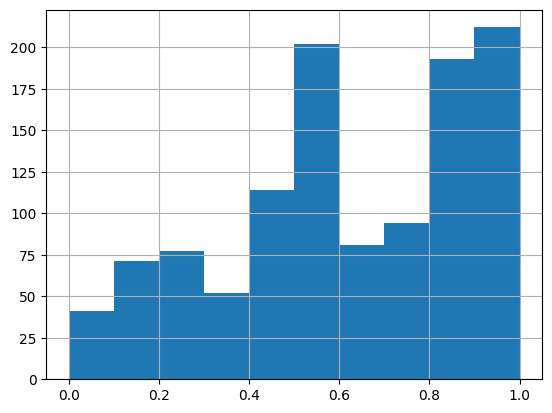

In [18]:
import matplotlib.pyplot as plt
df_new["recall_score"].hist()
plt.show()

In [19]:
df_new["duration_seconds"] = df_new["Duration"].str.extract(r"(\d+)").astype(float)

In [20]:
df_new.describe()

,video_id,recall_score,duration_seconds
count,1137.000000,1137.000000,1137.000000
mean,1365.331574,0.618417,33.394019
std,784.348327,0.284487,13.514451
min,1.000000,0.000000,6.000000
25%,781.000000,0.430000,25.000000
50%,1389.000000,0.670000,30.000000
75%,2041.000000,0.860000,45.000000
max,2711.000000,1.000000,59.000000


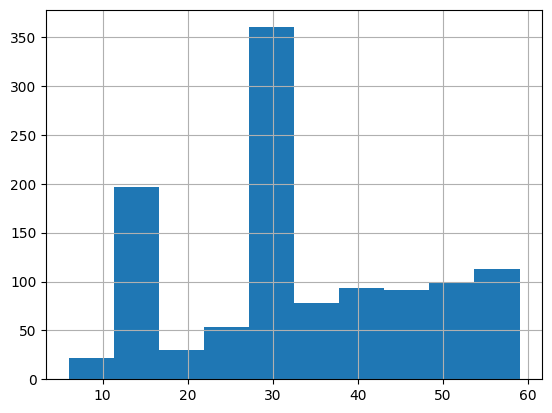

In [21]:
import matplotlib.pyplot as plt
df_new["duration_seconds"].hist()
plt.show()

In [22]:
correlation = df_new[
    ["duration_seconds", "recall_score"]
].corr(method="pearson")

print(correlation)

                  duration_seconds  recall_score
duration_seconds           1.00000       0.00568
recall_score               0.00568       1.00000


In [23]:
correlation = df_new[
    ["duration_seconds", "recall_score"]
].corr(method="spearman")

print(correlation)

                  duration_seconds  recall_score
duration_seconds          1.000000      0.004485
recall_score              0.004485      1.000000


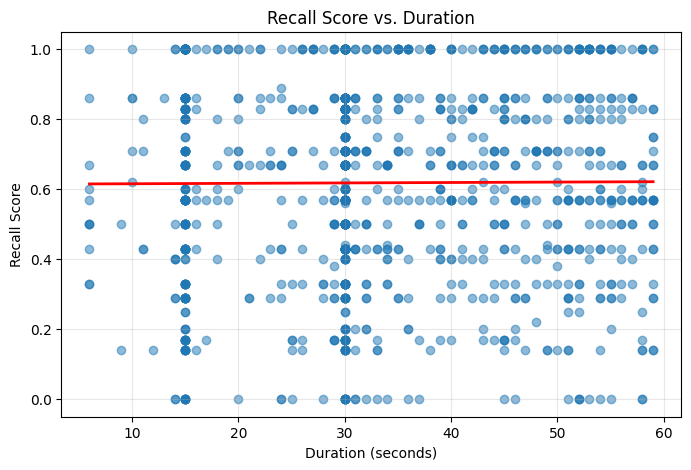

In [24]:
import numpy as np

plt.figure(figsize=(8, 5))
plt.scatter(df_new["duration_seconds"], df_new["recall_score"], alpha=0.5)

z = np.polyfit(df_new["duration_seconds"], df_new["recall_score"], 1)
x_line = np.linspace(df_new["duration_seconds"].min(), df_new["duration_seconds"].max(), 100)
plt.plot(x_line, np.poly1d(z)(x_line), color="red", linewidth=2)

plt.xlabel("Duration (seconds)")
plt.ylabel("Recall Score")
plt.title("Recall Score vs. Duration")
plt.grid(True, alpha=0.3)
plt.show()

In [25]:
df_new["Brand"].value_counts()

Brand
Netflix                       78
Walt-Disney                   72
Ulta Beauty                   41
Costco                        30
Amazon                        24
                              ..
Williams                       1
The Coffee Bean & Tea Leaf     1
American Family Insurance      1
Stanley Black&Decker           1
Dollar General                 1
Name: count, Length: 232, dtype: int64

In [26]:
brand_summary = pd.DataFrame({
    "Count": df_new["Brand"].value_counts(),
    "Percentage": df_new["Brand"].value_counts(normalize=True) * 100
})

brand_summary["Percentage"] = brand_summary["Percentage"].round(2)

print(brand_summary.head(10))

                       Count  Percentage
Brand                                   
Netflix                   78        6.86
Walt-Disney               72        6.33
Ulta Beauty               41        3.61
Costco                    30        2.64
Amazon                    24        2.11
Homedepot                 23        2.02
Adobe                     22        1.93
Dick'S Sporting Goods     21        1.85
Nvidia                    19        1.67
Wayfair                   18        1.58


In [27]:
brand_counts = df_new["Brand"].value_counts()

print("Number of brands:", df_new["Brand"].nunique())
print("Brands appearing once:", (brand_counts == 1).sum())
print("Brands with fewer than 5 ads:", (brand_counts < 5).sum())

Number of brands: 232
Brands appearing once: 54
Brands with fewer than 5 ads: 169


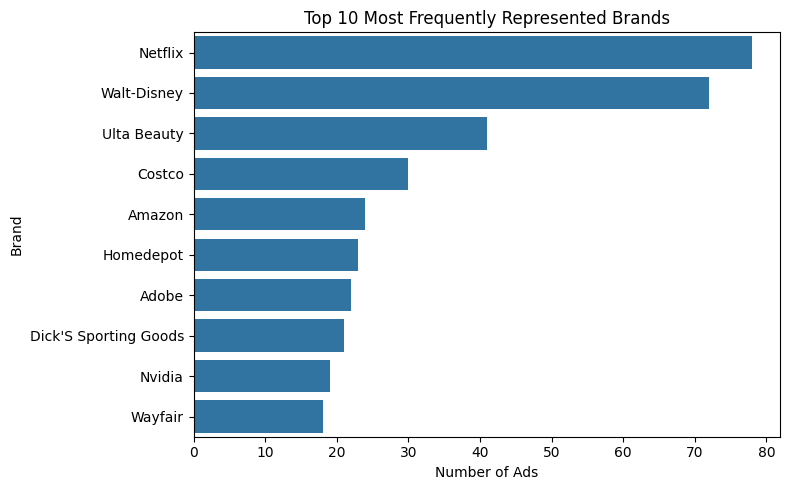

In [28]:
import seaborn as sns

top_10_brands = df_new["Brand"].value_counts().head(10)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=top_10_brands.values,
    y=top_10_brands.index,
)

plt.xlabel("Number of Ads")
plt.ylabel("Brand")
plt.title("Top 10 Most Frequently Represented Brands")
plt.tight_layout()
plt.show()

In [29]:
brand_recall_stats = (
    df_new.groupby("Brand")["recall_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .query("count >= 10")
    .sort_values("mean", ascending=False)
    .round(3)
)

brand_recall_stats

,count,mean,median,std
Brand,,,,
Redbull,16,0.962,1.000,0.091
Ford Motor Company,12,0.904,1.000,0.150
Fitbit,10,0.885,0.845,0.105
Netflix,78,0.880,1.000,0.178
Nvidia,19,0.847,0.860,0.162
Skechers,12,0.840,0.860,0.176
Uber Technologies,16,0.834,0.860,0.164
Walt-Disney,72,0.792,0.830,0.178
Amazon,24,0.786,0.775,0.140


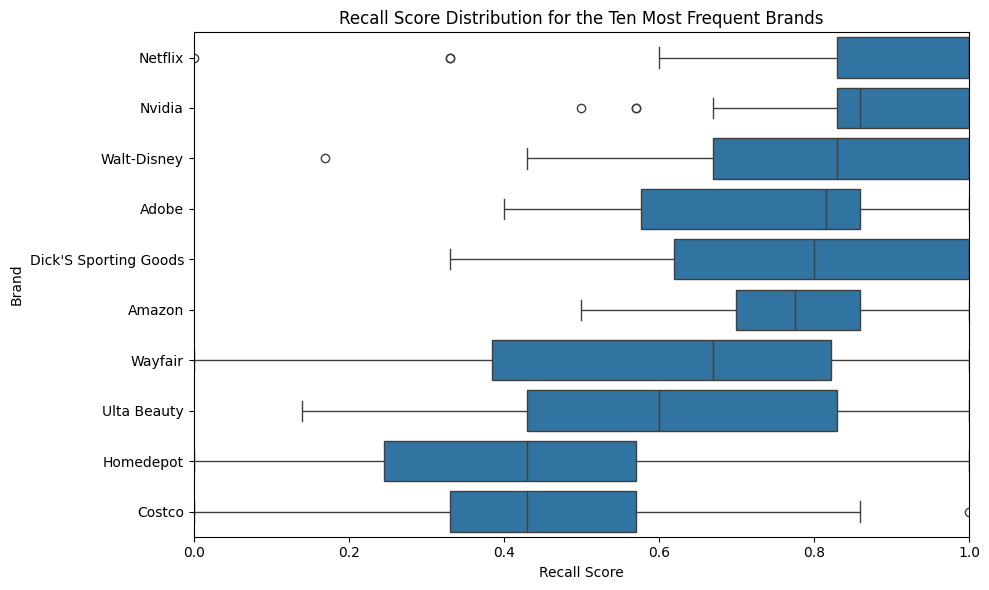

In [30]:
top_brands = df_new["Brand"].value_counts().head(10).index
top_brand_data = df_new[df_new["Brand"].isin(top_brands)].copy()

brand_order = (
    top_brand_data.groupby("Brand")["recall_score"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=top_brand_data,
    x="recall_score",
    y="Brand",
    order=brand_order,
   
)

plt.xlabel("Recall Score")
plt.ylabel("Brand")
plt.title("Recall Score Distribution for the Ten Most Frequent Brands")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [31]:
df_new["Pace"].value_counts()

Pace
low       716
medium    380
high       41
Name: count, dtype: int64

In [32]:
pace_summary = pd.DataFrame({
    "Count": df_new["Pace"].value_counts(),
    "Percentage": df_new["Pace"].value_counts(normalize=True) * 100
})

pace_summary["Percentage"] = pace_summary["Percentage"].round(2)
print(pace_summary)

        Count  Percentage
Pace                     
low       716       62.97
medium    380       33.42
high       41        3.61


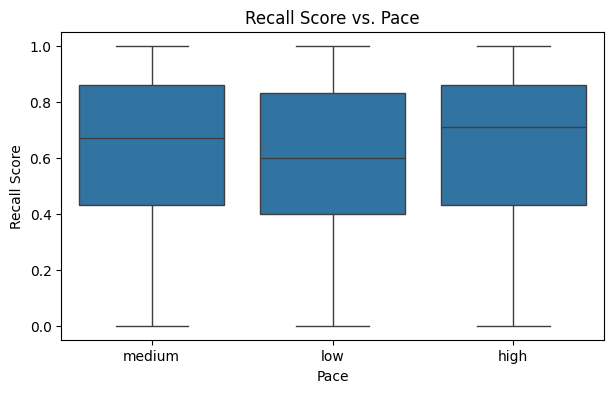

In [33]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df_new,
    x="Pace",
    y="recall_score",
)

plt.xlabel("Pace")
plt.ylabel("Recall Score")
plt.title("Recall Score vs. Pace")
plt.show()

In [34]:
df_new["Orientation"].value_counts()

Orientation
landscape    1107
portrait       18
square         12
Name: count, dtype: int64

In [35]:
orientation_summary = pd.DataFrame({
    "Count": df_new["Orientation"].value_counts(),
    "Percentage": df_new["Orientation"].value_counts(normalize=True) * 100
})

orientation_summary["Percentage"] = orientation_summary["Percentage"].round(2)

print(orientation_summary)

             Count  Percentage
Orientation                   
landscape     1107       97.36
portrait        18        1.58
square          12        1.06


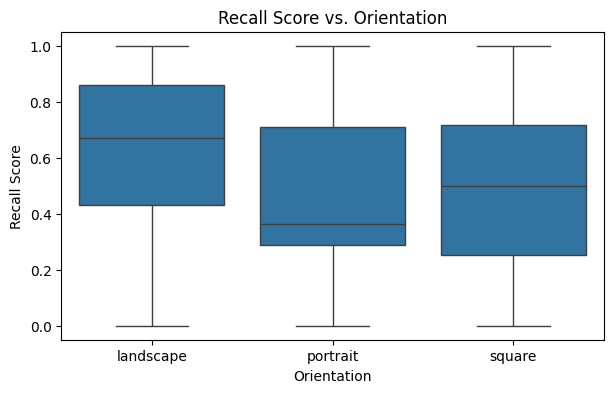

In [36]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df_new,
    x="Orientation",
    y="recall_score",
)

plt.xlabel("Orientation")
plt.ylabel("Recall Score")
plt.title("Recall Score vs. Orientation")
plt.show()

In [37]:
from collections import Counter

color_counts = Counter() 

df_new["scenes_colors"].dropna().apply(
    lambda x: color_counts.update([c.strip() for c in x.split(",") if c.strip()])
)

pd.Series(color_counts).sort_values(ascending=False)

Black           1006
Dark_Brown       953
Gray             928
Dark_Gray        869
White            789
Brown            761
Dark_Blue        689
Mud_Green        638
Olive            590
Off_White        573
Orange           529
Khaki            510
Light_Blue       492
Dark_Pink        480
Dark_Green       458
Silver           447
Royal_Blue       445
Dark_Red         398
Cyan             376
Pink             364
Red              359
Emerald          358
Lavender         288
Maroon           254
Cream            253
Purple           208
Tan              200
Blue             142
Light_Green      138
Mustard          118
Turquoise        109
Beige             95
Yellow            90
Green             90
Plum              90
Lilac             84
Gold              48
Bright_Green      44
Magenta           42
Violet            40
dtype: int64

In [38]:
color_series = df_new["scenes_colors"]

n_nan = color_series.isna().sum()


def is_empty_color(value):
    if value is None:
        return False  

    if isinstance(value, float) and np.isnan(value):
        return False  

    if isinstance(value, str):
        return value.strip() == ""

    if isinstance(value, (list, tuple, set, dict)):
        return len(value) == 0

    return False

empty_mask = color_series.apply(is_empty_color)
n_empty = empty_mask.sum()

n_total = len(df_new)
n_valid = n_total - n_nan - n_empty

print("Total ads:", n_total)
print("Valid color data:", n_valid)
print("NaN/None:", n_nan)
print("Empty values:", n_empty)
print("Missing or empty:", n_nan + n_empty)

Total ads: 1137
Valid color data: 1080
NaN/None: 0
Empty values: 57
Missing or empty: 57


In [39]:
top_colors = [color for color, count in color_counts.most_common(15)]

top_colors

['Black',
 'Dark_Brown',
 'Gray',
 'Dark_Gray',
 'White',
 'Brown',
 'Dark_Blue',
 'Mud_Green',
 'Olive',
 'Off_White',
 'Orange',
 'Khaki',
 'Light_Blue',
 'Dark_Pink',
 'Dark_Green']

In [40]:
top_15_colors = pd.DataFrame(
    color_counts.most_common(15),
    columns=["Color", "Count"]
)

total_occurrences = sum(color_counts.values())

top_15_colors["Percentage"] = (
    top_15_colors["Count"] / total_occurrences * 100
).round(2)

top_15_colors



,Color,Count,Percentage
0,Black,1006,6.56
1,Dark_Brown,953,6.21
2,Gray,928,6.05
3,Dark_Gray,869,5.66
4,White,789,5.14
5,Brown,761,4.96
6,Dark_Blue,689,4.49
7,Mud_Green,638,4.16
8,Olive,590,3.84
9,Off_White,573,3.73


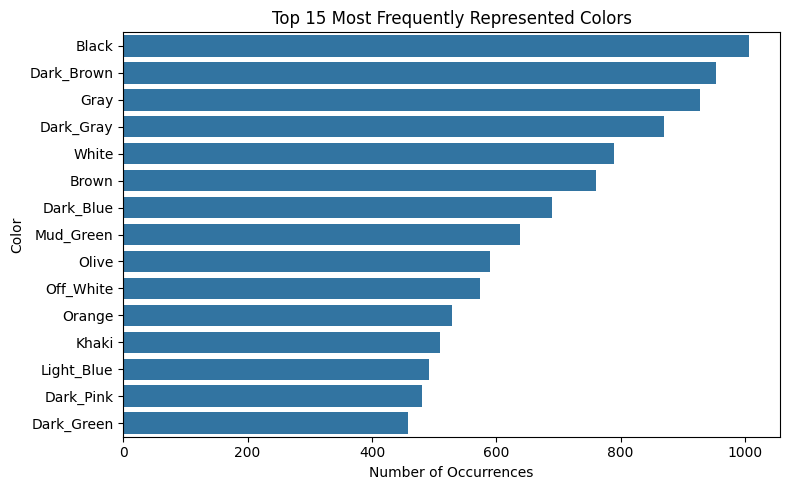

In [41]:
plt.figure(figsize=(8, 5))
import seaborn as sns
sns.barplot(
    data=top_15_colors,
    x="Count",
    y="Color"
)

plt.xlabel("Number of Occurrences")
plt.ylabel("Color")
plt.title("Top 15 Most Frequently Represented Colors")
plt.tight_layout()
plt.show()

In [42]:
df_color = df_new[["video_id", "recall_score"]].copy()
df_color.head()
for color in top_colors:
    df_color[f"color_{color}"] = df_new["scenes_colors"].fillna("").apply(
        lambda x: int(color in [c.strip() for c in x.split(",")])
    )

df_color.head()

,video_id,recall_score,color_Black,color_Dark_Brown,color_Gray,color_Dark_Gray,color_White,color_Brown,color_Dark_Blue,color_Mud_Green,color_Olive,color_Off_White,color_Orange,color_Khaki,color_Light_Blue,color_Dark_Pink,color_Dark_Green
1,37,0.80,1,1,0,0,0,1,0,1,1,0,1,1,0,0,0
3,1055,0.57,1,1,1,1,1,1,1,0,0,1,0,0,0,1,0
5,761,0.43,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1
7,2383,1.00,1,1,1,1,0,1,1,1,0,1,0,1,0,1,0
8,2084,1.00,1,0,1,1,1,0,1,0,0,0,0,0,1,0,0


In [43]:
top_colors_set = set(top_colors)

df_color["color_other"] = df_new["scenes_colors"].fillna("").apply(
    lambda value: int(
        any(
            color.strip() not in top_colors_set
            for color in value.split(",")
            if color.strip()
        )
    )
)

df_color.head()

,video_id,recall_score,color_Black,color_Dark_Brown,color_Gray,color_Dark_Gray,color_White,color_Brown,color_Dark_Blue,color_Mud_Green,color_Olive,color_Off_White,color_Orange,color_Khaki,color_Light_Blue,color_Dark_Pink,color_Dark_Green,color_other
1,37,0.80,1,1,0,0,0,1,0,1,1,0,1,1,0,0,0,1
3,1055,0.57,1,1,1,1,1,1,1,0,0,1,0,0,0,1,0,1
5,761,0.43,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1
7,2383,1.00,1,1,1,1,0,1,1,1,0,1,0,1,0,1,0,1
8,2084,1.00,1,0,1,1,1,0,1,0,0,0,0,0,1,0,0,1


In [44]:
df_color["color_other"].value_counts(normalize=True)

color_other
1    0.918206
0    0.081794
Name: proportion, dtype: float64

In [45]:
df_color = df_color.drop(columns="color_other")

               Color  Correlation  p-value
0        color_Black       0.0507   0.0876
7    color_Mud_Green       0.0499   0.0925
1   color_Dark_Brown       0.0293   0.3236
6    color_Dark_Blue       0.0274   0.3558
3    color_Dark_Gray       0.0270   0.3630
5        color_Brown       0.0230   0.4390
11       color_Khaki       0.0143   0.6303
14  color_Dark_Green       0.0133   0.6532
10      color_Orange      -0.0203   0.4942
13   color_Dark_Pink      -0.0383   0.1966
2         color_Gray      -0.0399   0.1784
9    color_Off_White      -0.0475   0.1092
12  color_Light_Blue      -0.0508   0.0871
8        color_Olive      -0.0867   0.0034
4        color_White      -0.0877   0.0031


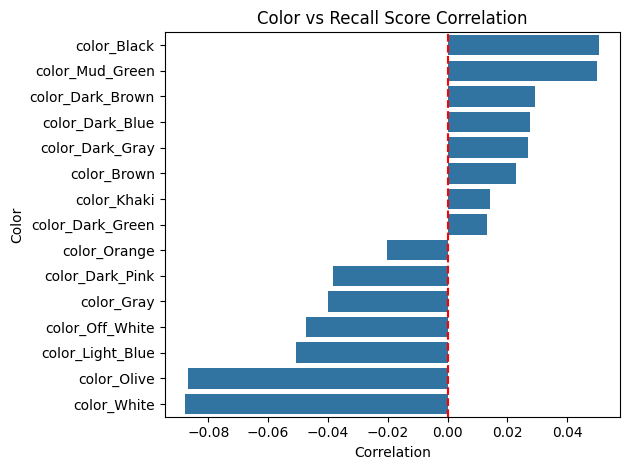

In [46]:
import seaborn as sns
from scipy.stats import pointbiserialr #Pearson Corr

color_cols = [c for c in df_color.columns if c.startswith("color_")]

results = []
for col in color_cols:
    corr, p_value = pointbiserialr(df_color[col], df_color["recall_score"].fillna(0))
    results.append({"Color": col, "Correlation": round(corr, 4), "p-value": round(p_value, 4)})

results_df = pd.DataFrame(results).sort_values("Correlation", ascending=False)
print(results_df)

sns.barplot(data=results_df, x="Correlation", y="Color")
plt.axvline(0, color="red", linestyle="--")
plt.title("Color vs Recall Score Correlation")
plt.tight_layout()
plt.show()

In [161]:
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

color_cols = [
    col for col in df_color.columns
    if col.startswith("color_") and col != "color_other"
]

formula = "recall_score ~ " + " + ".join(
    f'Q("{col}")' for col in color_cols
)

valid_color = (
    df_new["scenes_colors"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

df_color_anova = df_color.loc[valid_color].copy()

model = smf.ols(formula, data=df_color_anova).fit()

anova_results = anova_lm(model, typ=2)

anova_table = anova_results.loc[
    anova_results.index != "Residual",
    ["F", "PR(>F)"]
].copy()

anova_table.columns = ["F-statistic", "p-value"]

anova_table.index = [
    col.replace('Q("color_', '').replace('")', '').replace("_", " ")
    for col in anova_table.index
]

anova_table.index.name = "Color"

display(anova_table.round(4))

,F-statistic,p-value
Color,,
Black,3.6543,0.0562
Dark Brown,0.1388,0.7095
Gray,1.3916,0.2384
Dark Gray,0.3985,0.5280
White,5.1882,0.0229
Brown,0.4553,0.5000
Dark Blue,1.4765,0.2246
Mud Green,7.4568,0.0064
Olive,22.3837,0.0000


In [48]:
from collections import Counter

emotions_counts = Counter()  

df_new["scenes_emotions"].dropna().apply(
    lambda x: emotions_counts.update([c.strip() for c in x.split(",") if c.strip()])
)

pd.Series(emotions_counts).sort_values(ascending=False)

happy           423
gift            369
good            345
smiling         261
emergency       257
               ... 
a laugh           1
torticilli        1
pleasantness      1
faithful          1
crave             1
Length: 946, dtype: int64

In [49]:
top_emotions = [emotion for emotion, count in emotions_counts.most_common(15)]

top_emotions

['happy',
 'gift',
 'good',
 'smiling',
 'emergency',
 'togetherness',
 'casual',
 'achievement',
 'smile',
 'holiday',
 'danger',
 'cheerful',
 'bad',
 'fun',
 'problem']

In [50]:
df_emotions_exploded = (
    df_new[["video_id", "recall_score", "scenes_emotions"]]
    .copy()
)

df_emotions_exploded["scenes_emotions"] = (
    df_emotions_exploded["scenes_emotions"]
    .fillna("")
    .str.split(",")
)

df_emotions_exploded = df_emotions_exploded.explode("scenes_emotions")

df_emotions_exploded["scenes_emotions"] = (
    df_emotions_exploded["scenes_emotions"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_emotions_exploded = (
    df_emotions_exploded[
        df_emotions_exploded["scenes_emotions"] != ""
    ]
    .drop_duplicates(subset=["video_id", "scenes_emotions"])
)

top_emotions = (
    df_emotions_exploded["scenes_emotions"]
    .value_counts()
    .head(15)
    .index
)

emotion_recall_stats = (
    df_emotions_exploded[
        df_emotions_exploded["scenes_emotions"].isin(top_emotions)
    ]
    .groupby("scenes_emotions")["recall_score"]
    .agg(count="count", mean="mean", median="median", std="std")
    .sort_values("mean", ascending=False)
    .round(3)
)

emotion_recall_stats

,count,mean,median,std
scenes_emotions,,,,
fun,207,0.687,0.71,0.279
holiday,221,0.671,0.71,0.281
happy,423,0.662,0.71,0.269
bad,207,0.657,0.71,0.297
smile,227,0.655,0.71,0.277
danger,220,0.649,0.67,0.277
casual,250,0.647,0.67,0.276
gift,369,0.630,0.67,0.274
cheerful,209,0.628,0.67,0.274


In [51]:
df_emotions = df_new[["video_id", "recall_score"]].copy()
for emotion in top_emotions:
    df_emotions[f"emotion_{emotion}"] = df_new["scenes_emotions"].fillna("").apply(
        lambda x: int(emotion in [c.strip() for c in x.split(",")])
    )

df_emotions.head()

,video_id,recall_score,emotion_happy,emotion_gift,emotion_good,emotion_smiling,emotion_emergency,emotion_togetherness,emotion_casual,emotion_achievement,emotion_smile,emotion_holiday,emotion_danger,emotion_cheerful,emotion_fun,emotion_bad,emotion_problem
1,37,0.80,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1055,0.57,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0
5,761,0.43,1,1,0,0,0,0,1,0,0,1,0,0,0,0,0
7,2383,1.00,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0
8,2084,1.00,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


                 Emotion  Correlation  p-value
0          emotion_happy       0.1186   0.0001
12           emotion_fun       0.1136   0.0001
9        emotion_holiday       0.0904   0.0023
8          emotion_smile       0.0650   0.0284
13           emotion_bad       0.0639   0.0311
6         emotion_casual       0.0531   0.0733
10        emotion_danger       0.0526   0.0762
1           emotion_gift       0.0283   0.3404
11      emotion_cheerful       0.0167   0.5738
14       emotion_problem       0.0080   0.7871
5   emotion_togetherness       0.0024   0.9365
3        emotion_smiling      -0.0241   0.4169
7    emotion_achievement      -0.0242   0.4155
2           emotion_good      -0.0348   0.2409
4      emotion_emergency      -0.0912   0.0021


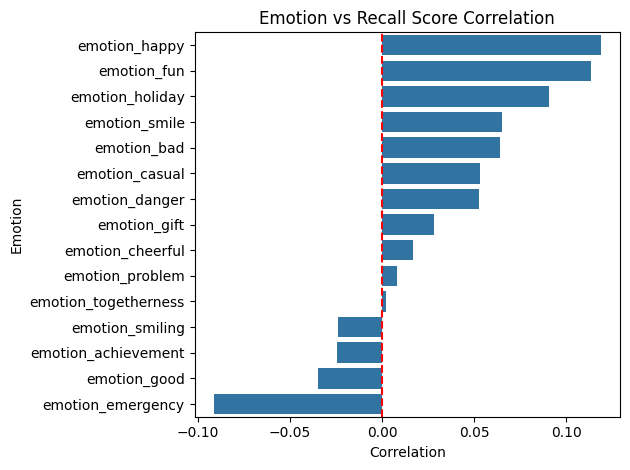

In [52]:
from scipy.stats import pointbiserialr #Pearson Corr

emotion_cols = [c for c in df_emotions.columns if c.startswith("emotion_")]

results = []
for col in emotion_cols:
    corr, p_value = pointbiserialr(df_emotions[col], df_emotions["recall_score"].fillna(0))
    results.append({"Emotion": col, "Correlation": round(corr, 4), "p-value": round(p_value, 4)})

results_df = pd.DataFrame(results).sort_values("Correlation", ascending=False)
print(results_df)

sns.barplot(data=results_df, x="Correlation", y="Emotion")
plt.axvline(0, color="red", linestyle="--")
plt.title("Emotion vs Recall Score Correlation")
plt.tight_layout()
plt.show()

In [53]:
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

emotion_cols = [
    col for col in df_emotions.columns
    if col.startswith("emotion_") and col != "emotion_other"
]

formula = "recall_score ~ " + " + ".join(
    f'Q("{col}")' for col in emotion_cols
)

model_emotion = smf.ols(
    formula, data=df_emotions
).fit()

anova_results_emotion = anova_lm(
    model_emotion, typ=2
)

anova_emotion_table = anova_results_emotion.loc[
    anova_results_emotion.index != "Residual",
    ["F", "PR(>F)"]
].copy()

anova_emotion_table.columns = [
    "F-statistic", "p-value"
]

anova_emotion_table.index = [
    col.replace('Q("emotion_', '')
       .replace('")', '')
       .replace("_", " ")
    for col in anova_emotion_table.index
]

anova_emotion_table.index.name = "Emotion"

display(anova_emotion_table.round(4))

,F-statistic,p-value
Emotion,,
happy,11.9953,0.0006
gift,0.0006,0.9800
good,1.8186,0.1778
smiling,7.9393,0.0049
emergency,6.2857,0.0123
togetherness,0.1890,0.6638
casual,1.0521,0.3052
achievement,0.2064,0.6497
smile,0.7251,0.3947


In [54]:
emotion = df_new["scenes_emotions"]

def is_missing(value):
    if value is None:
        return True
    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return True
    if isinstance(value, str):
        return value.strip() in ("", "[]", "{}", "None", "nan")
    if isinstance(value, (list, tuple, set, dict)):
        return len(value) == 0
    return False

missing_emotion = emotion.apply(is_missing)

print("Total ads:", len(df_new))
print("Missing Emotion:", missing_emotion.sum())
print("Valid Emotion:", (~missing_emotion).sum())
print("Missing percentage:", round(missing_emotion.mean() * 100, 2), "%")

Total ads: 1137
Missing Emotion: 0
Valid Emotion: 1137
Missing percentage: 0.0 %


In [55]:
#ANOVA 

In [56]:
top_15_brands = df_new["Brand"].value_counts().head(15).index
df_brand_top15 = df_new[df_new["Brand"].isin(top_15_brands)].copy()
print(df_brand_top15["Brand"].value_counts())

Brand
Netflix                  78
Walt-Disney              72
Ulta Beauty              41
Costco                   30
Amazon                   24
Homedepot                23
Adobe                    22
Dick'S Sporting Goods    21
Nvidia                   19
Wayfair                  18
Uber Technologies        16
Bedbath&Beyond           16
Redbull                  16
Cisco Systems            16
At&T                     14
Name: count, dtype: int64


In [57]:
from scipy.stats import f_oneway

top_15_brands = df_new["Brand"].value_counts().head(15).index

df_brand_anova = df_new.copy()

df_brand_anova["Brand_grouped"] = (
    df_brand_anova["Brand"]
    .where(df_brand_anova["Brand"].isin(top_15_brands), "Other")
)

brand_groups = [
    group["recall_score"].dropna().values
    for _, group in df_brand_anova.groupby("Brand_grouped")
]

f_stat, p_value = f_oneway(*brand_groups)

print("Number of groups:", len(brand_groups))
print(f"F-statistic: {f_stat:}")
print(f"p-value: {p_value:}")

Number of groups: 16
F-statistic: 17.75242952013594
p-value: 1.2429468284271825e-42


In [58]:
pace_summary = (
    df_new.groupby("Pace")["recall_score"]
    .agg(["count", "mean", "std"])
    .sort_values("mean", ascending=False)
)

pace_summary

,count,mean,std
Pace,,,
high,41,0.663659,0.279864
medium,380,0.654079,0.275111
low,716,0.596899,0.287801


In [59]:
pace_groups = [
    group["recall_score"].dropna().values
    for _, group in df_new.groupby("Pace")
]

f_stat_pace, p_value_pace = f_oneway(*pace_groups)

print(f"F-statistic Pace: {f_stat_pace:.3f}")
print(f"p-value Pace: {p_value_pace:.4f}")


F-statistic Pace: 5.597
p-value Pace: 0.0038


In [60]:
orientation_summary = (
    df_new.groupby("Orientation")["recall_score"]
    .agg(["count", "mean", "std"])
    .sort_values("mean", ascending=False)
)

orientation_summary

,count,mean,std
Orientation,,,
landscape,1107,0.621798,0.282911
portrait,18,0.499444,0.302703
square,12,0.485000,0.354003


In [61]:
orientation_groups = [
    group["recall_score"].dropna().values
    for _, group in df_new.groupby("Orientation")
]
f_stat_orientation, p_value_orientation = f_oneway(*orientation_groups)

print(f"F-statistic Orientation: {f_stat_orientation:.3f}")
print(f"p-value Orientation: {p_value_orientation:.4f}")

F-statistic Orientation: 2.982
p-value Orientation: 0.0511


In [62]:
#Spearman & Pearson: Duration vs Recall Score

In [63]:
from scipy.stats import pearsonr, spearmanr

data = df_new[["duration_seconds", "recall_score"]].dropna()

pearson_r, pearson_p = pearsonr(
    data["duration_seconds"], data["recall_score"]
)

spearman_rho, spearman_p = spearmanr(
    data["duration_seconds"], data["recall_score"]
)

print(f"Pearson:  r = {pearson_r:.3f}, p = {pearson_p:.4f}")
print(f"Spearman: ρ = {spearman_rho:.3f}, p = {spearman_p:.4f}")

Pearson:  r = 0.006, p = 0.8483
Spearman: ρ = 0.004, p = 0.8799


In [64]:
df_new.head()

,video_id,recall_score,youtube_id,Audio,Brand,Duration,Orientation,Pace,scenes_colors,scenes_emotions,duration_seconds
1,37,0.80,3DK8I80Yhgs,"Two full meals, $5.99 each. Marparoya, crispy ...",Burger King,15 second,landscape,medium,"Beige, Black, Brown, Cream, Dark_Brown, Dark_R...",", bitter, confidence, confident, delicious, di...",15.0
3,1055,0.57,2ZsxgpRMBDg,"Who doesn't dream about having smooth, silky, ...",Ulta Beauty,39 second,landscape,low,"Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",", bad, care, comfort, comfortable, disgust, di...",39.0
5,761,0.43,00STtvbodn8,"When you shop at Burlington, you'll find the l...",Burlington Stores,30 second,landscape,low,"Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",", attentive, casual, fancy, fantasy, friendly,...",30.0
7,2383,1.00,lgskk192v8Q,It's time that I told you the story of Aladdin...,Walt-Disney,30 second,landscape,medium,"Black, Brown, Dark_Blue, Dark_Brown, Dark_Gray...",", adventure, adversity, amusing, celebration, ...",30.0
8,2084,1.00,pdsBuJu7fnQ,You might be interested to know that your vehi...,Ford Motor Company,54 second,landscape,low,"Black, Dark_Blue, Dark_Gray, Gray, Lavender, L...","accident, amazement, dangerous, emergency",54.0


In [65]:
print(df_new.columns.tolist())

['video_id', 'recall_score', 'youtube_id', 'Audio', 'Brand', 'Duration', 'Orientation', 'Pace', 'scenes_colors', 'scenes_emotions', 'duration_seconds']


In [66]:
#train/val/test: 60/20/20

In [67]:
from sklearn.model_selection import train_test_split
from collections import Counter
import pandas as pd

# 1. Train / Validation / Test split (60/20/20)
train_val_df, test_df = train_test_split(
    df_new, test_size=0.20, random_state=42
)

train_df, val_df = train_test_split(
    train_val_df, test_size=0.25, random_state=42
)

train_df, val_df, test_df = (
    x.copy() for x in (train_df, val_df, test_df)
)

# 2. Select categories using TRAIN SET only
top_15_brands_train = (
    train_df["Brand"].value_counts().head(15).index.tolist()
)

brand_reference = "Other"
brand_levels = [brand_reference] + top_15_brands_train

# Most frequent categories as reference
pace_reference = train_df["Pace"].value_counts().idxmax()
orientation_reference = train_df["Orientation"].value_counts().idxmax()

pace_levels = [pace_reference] + [
    p for p in train_df["Pace"].dropna().unique()
    if p != pace_reference
]

orientation_levels = [orientation_reference] + [
    o for o in train_df["Orientation"].dropna().unique()
    if o != orientation_reference
]

# 3. Color and Emotion labels
def split_labels(value, lowercase=False):
    if not isinstance(value, str):
        return []
    labels = [v.strip() for v in value.split(",") if v.strip()]
    return [v.lower() for v in labels] if lowercase else labels

def top_scene_labels(series, n=15, lowercase=False):
    counts = Counter(
        label
        for value in series
        for label in split_labels(value, lowercase)
    )
    return [label for label, _ in counts.most_common(n)]

top_colors_train = top_scene_labels(
    train_df["scenes_colors"]
)

top_emotions_train = top_scene_labels(
    train_df["scenes_emotions"],
    lowercase=True
)

# 4. Define feature lists
brand_feature = [
    f"Brand_grouped_{b}" for b in brand_levels[1:]
]

Pace_feature = [
    f"Pace_{p}" for p in pace_levels[1:]
]

Orientation_feature = [
    f"Orientation_{o}" for o in orientation_levels[1:]
]

color_feature = [
    f"color_{c}" for c in top_colors_train
] + ["color_other", "color_missing"]

emotions_feature = [
    f"emotion_{e}" for e in top_emotions_train
] + ["emotion_other"]

# 5. Encode Train / Validation / Test
for split in (train_df, val_df, test_df):

    # Brand: Top 15 + Other
    split["Brand_grouped"] = split["Brand"].where(
        split["Brand"].isin(top_15_brands_train),
        "Other"
    )

    # One-hot encoding with drop_first=True
    for col, levels, prefix in [
        ("Brand_grouped", brand_levels, "Brand_grouped"),
        ("Pace", pace_levels, "Pace"),
        ("Orientation", orientation_levels, "Orientation")
    ]:
        encoded = pd.get_dummies(
            pd.Categorical(split[col], categories=levels),
            prefix=prefix,
            drop_first=True,
            dtype=int
        )

        encoded.index = split.index
        split[encoded.columns] = encoded

    # Multi-hot encoding for Colors and Emotions
    color_labels = split["scenes_colors"].apply(
        lambda x: set(split_labels(x))
    )

    # Separate missing Color information from observed colors outside Top 15
    split["color_missing"] = color_labels.apply(
        lambda labels: int(len(labels) == 0)
    )

    emotion_labels = split["scenes_emotions"].apply(
        lambda x: set(split_labels(x, lowercase=True))
    )

    for label in top_colors_train:
        split[f"color_{label}"] = color_labels.apply(
            lambda labels: int(label in labels)
        )

    split["color_other"] = color_labels.apply(
        lambda labels: int(bool(labels - set(top_colors_train)))
    )

    for label in top_emotions_train:
        split[f"emotion_{label}"] = emotion_labels.apply(
            lambda labels: int(label in labels)
        )

    split["emotion_other"] = emotion_labels.apply(
        lambda labels: int(bool(labels - set(top_emotions_train)))
    )

# 6. Check results
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nReference Brand:", brand_reference)
print("Reference Pace:", pace_reference)
print("Reference Orientation:", orientation_reference)

print("\nBrand features:", len(brand_feature))
print("Pace features:", Pace_feature)
print("Orientation features:", Orientation_feature)
print("Color features:", len(color_feature))
print("Missing Color counts:", {name: int(frame["color_missing"].sum()) for name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]})
print("Total missing Color:", sum(frame["color_missing"].sum() for frame in (train_df, val_df, test_df)))
print("Emotion features:", len(emotions_feature))

print("\nGeneral features:",
      1 + len(brand_feature)
      + len(Pace_feature)
      + len(Orientation_feature))

print("Visual features:",
      len(color_feature) + len(emotions_feature))

Train: (681, 64)
Validation: (228, 64)
Test: (228, 64)

Reference Brand: Other
Reference Pace: low
Reference Orientation: landscape

Brand features: 15
Pace features: ['Pace_medium', 'Pace_high']
Orientation features: ['Orientation_square', 'Orientation_portrait']
Color features: 17
Missing Color counts: {'Train': 35, 'Validation': 12, 'Test': 10}
Total missing Color: 57
Emotion features: 16

General features: 20
Visual features: 33


In [68]:
# Feature groups: fixed train-derived columns shared by all splits.
duration_feature = ["duration_seconds"]
general_feature = duration_feature + brand_feature + Pace_feature + Orientation_feature
visual_feature = color_feature + emotions_feature

for name, columns in {"General": general_feature, "Visual": visual_feature}.items():
    for split_name, split in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
        assert all(col in split.columns for col in columns), f"Missing {name} columns in {split_name}"
    print(f"{name}: {len(columns)} features, same encoding across Train/Validation/Test")


General: 20 features, same encoding across Train/Validation/Test
Visual: 33 features, same encoding across Train/Validation/Test


In [69]:
print("Brand:", len(brand_feature))
print("Pace:", len(Pace_feature))
print("Orientation:", len(Orientation_feature))
print("Color:", len(color_feature))
print("Emotion:", len(emotions_feature))

Brand: 15
Pace: 2
Orientation: 2
Color: 17
Emotion: 16


In [70]:
print("Pace columns:", Pace_feature)
print("Orientation columns:", Orientation_feature)

display(train_df[Pace_feature].head(10))
display(train_df[Orientation_feature].head(10))

print("Pace values:")
print(train_df[Pace_feature].dtypes)

print("Orientation values:")
print(train_df[Orientation_feature].dtypes)

Pace columns: ['Pace_medium', 'Pace_high']
Orientation columns: ['Orientation_square', 'Orientation_portrait']


,Pace_medium,Pace_high
424,1,0
1819,0,0
1483,0,0
775,0,0
1278,0,0
1137,0,0
1165,0,0
1419,0,0
1895,0,0
737,1,0


,Orientation_square,Orientation_portrait
424,0,0
1819,0,0
1483,0,0
775,0,0
1278,0,0
1137,0,0
1165,0,0
1419,0,0
1895,0,0
737,0,0


Pace values:
Pace_medium    int64
Pace_high      int64
dtype: object
Orientation values:
Orientation_square      int64
Orientation_portrait    int64
dtype: object


In [71]:
#TFIDF

In [72]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    stop_words="english"
)
X_train_tfidf = tfidf.fit_transform(train_df["Audio"])
X_val_tfidf = tfidf.transform(val_df["Audio"])
X_test_tfidf = tfidf.transform(test_df["Audio"])

In [73]:
import pandas as pd
import numpy as np
import re
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import r2_score

In [74]:
#BERT

In [75]:
model_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(model_name)
bert_model = AutoModel.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model = bert_model.to(device)

print("Device:", device)

Loading weights: 100%|██████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 220.87it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cpu


In [76]:
import torch
import numpy as np

def get_bert_embeddings(texts, batch_size=8, max_length=128):
    bert_model.eval()

    all_embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        encoded = bert_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)

        with torch.no_grad():
            outputs = bert_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        token_embeddings = outputs.last_hidden_state

        attention_mask_expanded = (
            attention_mask.unsqueeze(-1)
            .expand(token_embeddings.size())
            .float()
        )

        sum_embeddings = torch.sum(
            token_embeddings * attention_mask_expanded,
            dim=1
        )

        sum_mask = torch.clamp(
            attention_mask_expanded.sum(dim=1),
            min=1e-9
        )

        mean_embeddings = sum_embeddings / sum_mask

        all_embeddings.append(mean_embeddings.cpu().numpy())

    all_embeddings = np.vstack(all_embeddings)

    return all_embeddings


In [77]:
X_train_bert = get_bert_embeddings(
    train_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)

X_val_bert = get_bert_embeddings(
    val_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)

X_test_bert = get_bert_embeddings(
    test_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)

In [78]:
#distilbert

In [79]:
distilbert_model_name = "distilbert-base-uncased"

distilbert_tokenizer = AutoTokenizer.from_pretrained(distilbert_model_name)
distilbert_model = AutoModel.from_pretrained(distilbert_model_name)

distilbert_model = distilbert_model.to(device)
distilbert_model.eval()

Loading weights: 100%|██████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 343.58it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [80]:
def get_distilbert_embeddings(texts, batch_size=8, max_length=128):
    distilbert_model.eval()
    
    all_embeddings = []
    
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        
        encoded = distilbert_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )
        
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        
        with torch.no_grad():
            outputs = distilbert_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        
        token_embeddings = outputs.last_hidden_state
        
       
        attention_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        
        sum_embeddings = torch.sum(token_embeddings * attention_mask_expanded, dim=1)
        sum_mask = torch.clamp(attention_mask_expanded.sum(dim=1), min=1e-9)
        
        mean_embeddings = sum_embeddings / sum_mask
        
        all_embeddings.append(mean_embeddings.cpu().numpy())
    
    all_embeddings = np.vstack(all_embeddings)
    
    return all_embeddings

In [81]:
X_train_distilbert = get_distilbert_embeddings(
    train_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)

X_val_distilbert = get_distilbert_embeddings(
    val_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)

X_test_distilbert = get_distilbert_embeddings(
    test_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)

In [82]:
#RoBERTa

In [83]:
model_name = "roberta-base"

roberta_tokenizer = AutoTokenizer.from_pretrained(model_name)
roberta_model = AutoModel.from_pretrained(model_name)

roberta_model = roberta_model.to(device)
roberta_model.eval()

Loading weights: 100%|██████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 236.68it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RobertaModel(
  (embeddings): RobertaEmbeddings(
    (word_embeddings): Embedding(50265, 768, padding_idx=1)
    (token_type_embeddings): Embedding(1, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
    (position_embeddings): Embedding(514, 768, padding_idx=1)
  )
  (encoder): RobertaEncoder(
    (layer): ModuleList(
      (0-11): 12 x RobertaLayer(
        (attention): RobertaAttention(
          (self): RobertaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): RobertaSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=Tru

In [84]:
def get_roberta_embeddings(texts, batch_size=8, max_length=128):
    roberta_model.eval()
    
    all_embeddings = []
    
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        
        encoded = roberta_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )
        
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        
        with torch.no_grad():
            outputs = roberta_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        
        token_embeddings = outputs.last_hidden_state
        
        attention_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        sum_embeddings = torch.sum(token_embeddings * attention_mask_expanded, dim=1)
        sum_mask = torch.clamp(attention_mask_expanded.sum(dim=1), min=1e-9)
        mean_embeddings = sum_embeddings / sum_mask
        
        all_embeddings.append(mean_embeddings.cpu().numpy())
    
    return np.vstack(all_embeddings)

In [85]:
X_train_roberta = get_roberta_embeddings(
    train_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)

X_val_roberta = get_roberta_embeddings(
    val_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)

X_test_roberta = get_roberta_embeddings(
    test_df["Audio"].tolist(),
    batch_size=8,
    max_length=128
)


In [86]:
#MiniLM

In [87]:
from sentence_transformers import SentenceTransformer

minilm_model = SentenceTransformer("all-MiniLM-L6-v2")

X_train_minilm = minilm_model.encode(
    train_df["Audio"].fillna("").astype(str).tolist(),
    batch_size=8,
    show_progress_bar=True
)

X_val_minilm = minilm_model.encode(
    val_df["Audio"].fillna("").astype(str).tolist(),
    batch_size=8,
    show_progress_bar=True
)

X_test_minilm = minilm_model.encode(
    test_df["Audio"].fillna("").astype(str).tolist(),
    batch_size=8,
    show_progress_bar=True
)


Batches: 100%|█████████████████████████████████████████████████████████████████████████| 29/29 [00:04<00:00,  6.14it/s]


In [88]:
feature_sets = {
    "TF-IDF": (X_train_tfidf, X_val_tfidf, X_test_tfidf),
    "BERT": (X_train_bert, X_val_bert, X_test_bert),
    "DistilBERT": (X_train_distilbert, X_val_distilbert, X_test_distilbert),
    "RoBERTa": (X_train_roberta, X_val_roberta, X_test_roberta),
    "MiniLM": (X_train_minilm, X_val_minilm, X_test_minilm)
}

In [89]:
#LR: Duration vs RS

In [90]:
features = duration_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² Duration:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Duration:", round(r2_score(y_val, y_val_pred), 4))

Train R² Duration: 0.0012
Validation R² Duration: -0.0038


In [162]:
target = "recall_score"

feature_combinations = {
    "Brand + Orientation": brand_feature + Orientation_feature,
    "Brand + Pace + Orientation": brand_feature + Pace_feature + Orientation_feature
}

for name, features in feature_combinations.items():

    # Train
    X_train = train_df[features]
    y_train = train_df[target]

    # Validation
    X_val = val_df[features]
    y_val = val_df[target]

    # Linear Regression
    lr = LinearRegression()
    lr.fit(X_train, y_train)

    # Predictions
    y_train_pred = lr.predict(X_train)
    y_val_pred = lr.predict(X_val)

    # R²
    print(f"\n{name}")
    print("Train R²:", round(r2_score(y_train, y_train_pred), 4))
    print("Validation R²:", round(r2_score(y_val, y_val_pred), 4))


Brand + Orientation
Train R²: 0.2033
Validation R²: 0.1784

Brand + Pace + Orientation
Train R²: 0.2204
Validation R²: 0.2026


In [91]:
#LR: Brand vs RS

In [92]:
features = brand_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² Brand_grouped:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Brand_grouped:", round(r2_score(y_val, y_val_pred), 4))


Train R² Brand_grouped: 0.1938
Validation R² Brand_grouped: 0.1678


In [93]:
#LR: Pace vs RS

In [94]:
features = Pace_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² Pace:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Pace:", round(r2_score(y_val, y_val_pred), 4))


Train R² Pace: 0.0095
Validation R² Pace: 0.0233


In [95]:
#LR: Orientation vs RS

In [96]:
features = Orientation_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² Orientation:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Orientation:", round(r2_score(y_val, y_val_pred), 4))

Train R² Orientation: 0.0042
Validation R² Orientation: 0.0024


In [97]:
features = color_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² Color top 15:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Color top 15:", round(r2_score(y_val, y_val_pred), 4))

Train R² Color top 15: 0.0403
Validation R² Color top 15: 0.0014


In [98]:
features = emotions_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]


# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)


# R²
print("Train R² Emotion top 15:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Emotion top 15:", round(r2_score(y_val, y_val_pred), 4))


Train R² Emotion top 15: 0.0414
Validation R² Emotion top 15: 0.0313


In [99]:
features = emotions_feature + color_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]


# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² Emotion + Color top 15:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Emotion + Color top 15:", round(r2_score(y_val, y_val_pred), 4))

Train R² Emotion + Color top 15: 0.0765
Validation R² Emotion + Color top 15: 0.0294


In [100]:
features = emotions_feature + color_feature + brand_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² Brand + Emotion + Color top 15:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Brand + Emotion + Color top 15:", round(r2_score(y_val, y_val_pred), 4))


Train R² Brand + Emotion + Color top 15: 0.2304
Validation R² Brand + Emotion + Color top 15: 0.1844


In [101]:
features = Pace_feature + brand_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² Brand + Pace:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Brand + Pace:", round(r2_score(y_val, y_val_pred), 4))

Train R² Brand + Pace: 0.2101
Validation R² Brand + Pace: 0.1919


In [102]:
features = color_feature + brand_feature + emotions_feature + duration_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]


# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² color_feature + brand_feature + emotions_feature + duration_feature:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² color_feature + brand_feature + emotions_feature + duration_feature:", round(r2_score(y_val, y_val_pred), 4))

Train R² color_feature + brand_feature + emotions_feature + duration_feature: 0.2304
Validation R² color_feature + brand_feature + emotions_feature + duration_feature: 0.1836


In [103]:
features = color_feature + brand_feature + emotions_feature + duration_feature + Pace_feature + Orientation_feature
target = "recall_score"


# Train
X_train = train_df[features]
y_train = train_df[target]

# Validation
X_val = val_df[features]
y_val = val_df[target]


# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² all:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² all:", round(r2_score(y_val, y_val_pred), 4))

Train R² all: 0.2519
Validation R² all: 0.1973


In [104]:
features = "TF-IDF"
target = "recall_score"


X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² TF-IDF:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² TF-IDF:", round(r2_score(y_val, y_val_pred), 4))

Train R² TF-IDF: 0.987
Validation R² TF-IDF: -0.3462


In [105]:
features =  "BERT"
target = "recall_score"


X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)


# R²
print("Train R² BERT:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² BERT:", round(r2_score(y_val, y_val_pred), 4))

Train R² BERT: 0.9988
Validation R² BERT: -7.0248


In [106]:
features =  "DistilBERT"
target = "recall_score"


X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)


# R²
print("Train R² DistilBERT:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² DistilBERT:", round(r2_score(y_val, y_val_pred), 4))

Train R² DistilBERT: 0.9988
Validation R² DistilBERT: -9.6423


In [107]:
features =  "RoBERTa"
target = "recall_score"


X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² RoBERTa:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² RoBERTa:", round(r2_score(y_val, y_val_pred), 4))


Train R² RoBERTa: 0.999
Validation R² RoBERTa: -9.2


In [108]:
features =  "MiniLM"
target = "recall_score"


X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]


# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_val_pred = lr.predict(X_val)

# R²
print("Train R² MiniLM:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² MiniLM:", round(r2_score(y_val, y_val_pred), 4))

Train R² MiniLM: 0.6023
Validation R² MiniLM: -0.7939


In [109]:
#Random Forest

In [110]:
from sklearn.ensemble import RandomForestRegressor

features = duration_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² duration_feature:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² duration_feature:", round(r2_score(y_val, y_val_pred), 4))

Train R² duration_feature: 0.0421
Validation R² duration_feature: -0.0407


In [111]:
from sklearn.ensemble import RandomForestRegressor

features = brand_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)


print("Train R² brand_feature:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² brand_feature:", round(r2_score(y_val, y_val_pred), 4))

Train R² brand_feature: 0.1073
Validation R² brand_feature: 0.1213


In [112]:
from sklearn.ensemble import RandomForestRegressor

features = Pace_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² Pace_feature:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Pace_feature:", round(r2_score(y_val, y_val_pred), 4))

Train R² Pace_feature: 0.0095
Validation R² Pace_feature: 0.0237


In [113]:
from sklearn.ensemble import RandomForestRegressor

features = Orientation_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² Orientation_feature:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² Orientation_feature:", round(r2_score(y_val, y_val_pred), 4))

Train R² Orientation_feature: 0.0004
Validation R² Orientation_feature: -0.0025


In [114]:
features = color_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² color_feature:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² color_feature:", round(r2_score(y_val, y_val_pred), 4))

Train R² color_feature: 0.0807
Validation R² color_feature: 0.0072


In [115]:
features = emotions_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² emotions_feature:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² emotions_feature:", round(r2_score(y_val, y_val_pred), 4))

Train R² emotions_feature: 0.0733
Validation R² emotions_feature: 0.0242


In [116]:
features = brand_feature + duration_feature + Pace_feature + Orientation_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² General :", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² General:", round(r2_score(y_val, y_val_pred), 4))

Train R² General : 0.1218
Validation R² General: 0.1285


In [117]:
features = brand_feature + Orientation_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² brand_feature + Orientation_feature  :", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² brand_feature + Orientation_feature :", round(r2_score(y_val, y_val_pred), 4))

Train R² brand_feature + Orientation_feature  : 0.1076
Validation R² brand_feature + Orientation_feature : 0.1215


In [118]:
features = brand_feature + Pace_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² brand_feature + Pace_feature  :", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² brand_feature + Pace_feature :", round(r2_score(y_val, y_val_pred), 4))

Train R² brand_feature + Pace_feature  : 0.1153
Validation R² brand_feature + Pace_feature : 0.1356


In [163]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

target = "recall_score"

feature_combinations = {
    "Brand + Pace + Orientation": brand_feature + Pace_feature + Orientation_feature,
    "Brand + Visual": brand_feature + color_feature + emotions_feature
}

for name, features in feature_combinations.items():

    # Train
    X_train = train_df[features]
    y_train = train_df[target]

    # Validation
    X_val = val_df[features]
    y_val = val_df[target]

    # Random Forest
    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=10,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    # Predictions
    y_train_pred = rf.predict(X_train)
    y_val_pred = rf.predict(X_val)

    # R²
    print(f"\n{name}")
    print("Train R²:", round(r2_score(y_train, y_train_pred), 4))
    print("Validation R²:", round(r2_score(y_val, y_val_pred), 4))


Brand + Pace + Orientation
Train R²: 0.1161
Validation R²: 0.137

Brand + Visual
Train R²: 0.1505
Validation R²: 0.1254


In [120]:
features = emotions_feature + color_feature + brand_feature + duration_feature + Pace_feature + Orientation_feature
target = "recall_score"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

print("Train R² all:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² all:", round(r2_score(y_val, y_val_pred), 4))

Train R² all: 0.1543
Validation R² all: 0.1282


In [121]:
features = "TF-IDF"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]



rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)


# R²
print("Train R² TF-IDF:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² TF-IDF:", round(r2_score(y_val, y_val_pred), 4))

Train R² TF-IDF: 0.0996
Validation R² TF-IDF: 0.0458


In [122]:
features =  "BERT"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]



rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)
# R²
print("Train R² BERT:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² BERT:", round(r2_score(y_val, y_val_pred), 4))

Train R² BERT: 0.3752
Validation R² BERT: 0.0769


In [123]:
features =  "DistilBERT"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

# R²
print("Train R² DistilBERT:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² DistilBERT:", round(r2_score(y_val, y_val_pred), 4))


Train R² DistilBERT: 0.3755
Validation R² DistilBERT: 0.082


In [124]:
features =  "RoBERTa"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

# R²
print("Train R² RoBERTa:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² RoBERTa:", round(r2_score(y_val, y_val_pred), 4))

Train R² RoBERTa: 0.386
Validation R² RoBERTa: 0.0967


In [125]:
features =  "MiniLM"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

# R²
print("Train R² MiniLM:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² MiniLM:", round(r2_score(y_val, y_val_pred), 4))

Train R² MiniLM: 0.3672
Validation R² MiniLM: 0.0639


In [126]:
#RoBERTa + Brand

In [127]:
import numpy as np

# ROBERTa
X_train_text = X_train_roberta
X_val_text = X_val_roberta


# Brand
X_train_brand = train_df[brand_feature].to_numpy()
X_val_brand = val_df[brand_feature].to_numpy()


# Combine ROBERTa + Brand
X_train = np.hstack([X_train_text, X_train_brand])
X_val = np.hstack([X_val_text, X_val_brand])


# Target
y_train = train_df["recall_score"]
y_val = val_df["recall_score"]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

# R²
print("Train R² ROBERTa + Brand:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R² ROBERTa + Brand", round(r2_score(y_val, y_val_pred), 4))

Train R² ROBERTa + Brand: 0.3778
Validation R² ROBERTa + Brand 0.1069


In [128]:
rf_metadata_sets = {
    "Duration": duration_feature,
    "Brand": brand_feature,
    "Pace": Pace_feature,
    "Orientation": Orientation_feature,
    "Color": color_feature,
    "Emotion": emotions_feature,

    "Brand + Pace":
        brand_feature + Pace_feature,

    "Brand + Orientation":
        brand_feature + Orientation_feature,

    "Brand + Duration":
        brand_feature + duration_feature,

    "General":
        duration_feature
        + brand_feature
        + Pace_feature
        + Orientation_feature,

    "Visual":
        emotions_feature + color_feature,

    "Brand + Visual":
        brand_feature
        + emotions_feature
        + color_feature,

    "Brand + Visual + Duration":
        brand_feature
        + emotions_feature
        + color_feature
        + duration_feature,

    "General + Visual":
        duration_feature
        + brand_feature
        + Pace_feature
        + Orientation_feature
        + emotions_feature
        + color_feature
}

In [129]:
features = "Brand + Pace"

metadata_cols = rf_metadata_sets[features]

X_train = np.hstack([
    X_train_roberta,
    train_df[metadata_cols].to_numpy()
])

X_val = np.hstack([
    X_val_roberta,
    val_df[metadata_cols].to_numpy()
])


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

train_pred = rf.predict(X_train)
val_pred = rf.predict(X_val)

print("roberta +", features)
print("Train R²:", round(r2_score(y_train, train_pred), 4))
print("Validation R²:", round(r2_score(y_val, val_pred), 4))

roberta + Brand + Pace
Train R²: 0.3793
Validation R²: 0.1158


In [130]:
features = "Brand + Orientation"

metadata_cols = rf_metadata_sets[features]

X_train = np.hstack([
    X_train_roberta,
    train_df[metadata_cols].to_numpy()
])

X_val = np.hstack([
    X_val_roberta,
    val_df[metadata_cols].to_numpy()
])


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

train_pred = rf.predict(X_train)
val_pred = rf.predict(X_val)

print("ROBERTa +", features)
print("Train R²:", round(r2_score(y_train, train_pred), 4))
print("Validation R²:", round(r2_score(y_val, val_pred), 4))

ROBERTa + Brand + Orientation
Train R²: 0.3813
Validation R²: 0.1165


In [131]:
features =  "Brand + Duration"

metadata_cols = rf_metadata_sets[features]

X_train = np.hstack([
    X_train_roberta,
    train_df[metadata_cols].to_numpy()
])

X_val = np.hstack([
    X_val_roberta,
    val_df[metadata_cols].to_numpy()
])




rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

train_pred = rf.predict(X_train)
val_pred = rf.predict(X_val)

print("roberta +", features)
print("Train R²:", round(r2_score(y_train, train_pred), 4))
print("Validation R²:", round(r2_score(y_val, val_pred), 4))

roberta + Brand + Duration
Train R²: 0.3786
Validation R²: 0.1117


In [132]:
features =  "General"

metadata_cols = rf_metadata_sets[features]

X_train = np.hstack([
    X_train_roberta,
    train_df[metadata_cols].to_numpy()
])

X_val = np.hstack([
    X_val_roberta,
    val_df[metadata_cols].to_numpy()
])


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

train_pred = rf.predict(X_train)
val_pred = rf.predict(X_val)

print("roberta +", features)
print("Train R²:", round(r2_score(y_train, train_pred), 4))
print("Validation R²:", round(r2_score(y_val, val_pred), 4))

roberta + General
Train R²: 0.3781
Validation R²: 0.1185


In [133]:
features =  "Visual"

metadata_cols = rf_metadata_sets[features]

X_train = np.hstack([
    X_train_roberta,
    train_df[metadata_cols].to_numpy()
])

X_val = np.hstack([
    X_val_roberta,
    val_df[metadata_cols].to_numpy()
])


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

train_pred = rf.predict(X_train)
val_pred = rf.predict(X_val)

print("roberta +", features)
print("Train R²:", round(r2_score(y_train, train_pred), 4))
print("Validation R²:", round(r2_score(y_val, val_pred), 4))

roberta + Visual
Train R²: 0.3868
Validation R²: 0.0933


In [134]:
features =  "Brand + Visual + Duration"

metadata_cols = rf_metadata_sets[features]

X_train = np.hstack([
    X_train_roberta,
    train_df[metadata_cols].to_numpy()
])

X_val = np.hstack([
    X_val_roberta,
    val_df[metadata_cols].to_numpy()
])



rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

train_pred = rf.predict(X_train)
val_pred = rf.predict(X_val)

print("roberta +", features)
print("Train R²:", round(r2_score(y_train, train_pred), 4))
print("Validation R²:", round(r2_score(y_val, val_pred), 4))


roberta + Brand + Visual + Duration
Train R²: 0.3794
Validation R²: 0.117


In [135]:
features =  "General + Visual"

metadata_cols = rf_metadata_sets[features]

X_train = np.hstack([
    X_train_roberta,
    train_df[metadata_cols].to_numpy()
])

X_val = np.hstack([
    X_val_roberta,
    val_df[metadata_cols].to_numpy()
])


rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

train_pred = rf.predict(X_train)
val_pred = rf.predict(X_val)


print("roberta +", features)
print("Train R²:", round(r2_score(y_train, train_pred), 4))
print("Validation R²:", round(r2_score(y_val, val_pred), 4))

roberta + General + Visual
Train R²: 0.38
Validation R²: 0.1134


In [136]:
#roberta + Brand + Color + Emotion

In [137]:
feature_sets["roberta + Brand + Color + Emotion"] = (
    np.hstack([
        X_train_roberta,
        train_df[brand_feature].to_numpy(),
        train_df[color_feature].to_numpy(),
        train_df[emotions_feature].to_numpy()
    ]),

    np.hstack([
        X_val_roberta,
        val_df[brand_feature].to_numpy(),
        val_df[color_feature].to_numpy(),
        val_df[emotions_feature].to_numpy()
    ]),

)

features = "roberta + Brand + Color + Emotion"
target = "recall_score"

X_train, X_val = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=10,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

# R²
print("Train R² roberta + Brand + Color + Emotion:", round(r2_score(y_train, y_train_pred), 4))
print("Validation R²roberta + Brand + Color + Emotion", round(r2_score(y_val, y_val_pred), 4))

Train R² roberta + Brand + Color + Emotion: 0.3791
Validation R²roberta + Brand + Color + Emotion 0.1201


In [138]:
#RIDGE

In [139]:
general_feature = (
    duration_feature
    + brand_feature
    + Pace_feature
    + Orientation_feature
)

visual_feature = (
    color_feature
    + emotions_feature
)

ridge_feature_groups = {
    "Duration": duration_feature,
    "Brand": brand_feature,
    "Pace": Pace_feature,
    "Orientation": Orientation_feature,
    "Color": color_feature,
    "Emotion": emotions_feature,
    "General": general_feature,
    "Visual": visual_feature,
    "General + Visual": general_feature + visual_feature
}

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

ridge_results = []

for feature_name, columns in ridge_feature_groups.items():

    X_train = train_df[columns]
    X_val = val_df[columns]

    y_train = train_df["recall_score"]
    y_val = val_df["recall_score"]

    for alpha in alpha_values:

        numeric_cols = [col for col in duration_feature if col in columns]
        binary_cols = [col for col in columns if col not in numeric_cols]
        preprocessor = ColumnTransformer([
            ("duration", StandardScaler(), numeric_cols),
            ("binary", "passthrough", binary_cols)
        ])
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("ridge", Ridge(alpha=alpha))
        ])
        model.fit(X_train, y_train)

        train_preds = model.predict(X_train)
        val_preds = model.predict(X_val)

        ridge_results.append({
            "Feature": feature_name,
            "Alpha": alpha,
            "Train R²": r2_score(y_train, train_preds),
            "Validation R²": r2_score(y_val, val_preds)
        })

ridge_results_df = pd.DataFrame(ridge_results)

best_ridge_results = (
    ridge_results_df
    .sort_values("Validation R²", ascending=False)
    .drop_duplicates(subset="Feature")
)

best_ridge_results


,Feature,Alpha,Train R²,Validation R²
56,General,1.00,0.219451,0.201548
74,General + Visual,1.00,0.250282,0.199083
11,Brand,1.00,0.192716,0.169318
68,Visual,50.00,0.068001,0.035603
49,Emotion,10.00,0.040271,0.032554
18,Pace,0.01,0.009494,0.023307
42,Color,100.00,0.030956,0.004957
27,Orientation,0.01,0.004186,0.002406
8,Duration,200.00,0.001170,-0.003322


In [140]:
feature_sets = {
    "Duration": (
        train_df[duration_feature],
        val_df[duration_feature],
        test_df[duration_feature]
    ),

    "Brand": (
        train_df[brand_feature],
        val_df[brand_feature],
        test_df[brand_feature]
    ),

    "Pace": (
        train_df[Pace_feature],
        val_df[Pace_feature],
        test_df[Pace_feature]
    ),

    "Orientation": (
        train_df[Orientation_feature],
        val_df[Orientation_feature],
        test_df[Orientation_feature]
    ),

    "Color": (
        train_df[color_feature],
        val_df[color_feature],
        test_df[color_feature]
    ),

    "Emotion": (
        train_df[emotions_feature],
        val_df[emotions_feature],
        test_df[emotions_feature]
    ),

    "TF-IDF": (
        X_train_tfidf,
        X_val_tfidf,
        X_test_tfidf
     ),
    
    "BERT": (
        X_train_bert,
        X_val_bert,
        X_test_bert
    ),

    "DistilBERT": (
        X_train_distilbert,
        X_val_distilbert,
        X_test_distilbert
    ),

    "RoBERTa": (
        X_train_roberta,
        X_val_roberta,
        X_test_roberta
    ),

    "MiniLM": (
        X_train_minilm,
        X_val_minilm,
        X_test_minilm
    )
}

In [141]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
import pandas as pd

language_models = [
    "TF-IDF",
    "BERT",
    "DistilBERT",
    "RoBERTa",
    "MiniLM"
]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

language_results = []

for features in language_models:

    X_train, X_val = feature_sets[features][:2]

    y_train = train_df["recall_score"]
    y_val = val_df["recall_score"]

    for alpha in alpha_values:

        model = Ridge(alpha=alpha)
        model.fit(X_train, y_train)

        train_preds = model.predict(X_train)
        val_preds = model.predict(X_val)

        language_results.append({
            "Feature": features,
            "Alpha": alpha,
            "Train R²": r2_score(y_train, train_preds),
            "Validation R²": r2_score(y_val, val_preds)
        })

language_results_df = pd.DataFrame(language_results)

best_language_results = (
    language_results_df
    .sort_values("Validation R²", ascending=False)
    .drop_duplicates(subset="Feature")
)

display(best_language_results)

,Feature,Alpha,Train R²,Validation R²
15,BERT,100.0,0.243077,0.108428
24,DistilBERT,100.0,0.189802,0.103970
39,MiniLM,5.0,0.244811,0.094419
31,RoBERTa,10.0,0.297604,0.091852
3,TF-IDF,5.0,0.317518,0.051116


In [142]:
from sklearn.linear_model import Ridge
features = "BERT"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

alpha_values = [0.01, 0.1, 1.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature BERT": features,
        "Alpha BERT": alpha,
        "Train R² BERT": r2_score(y_train, train_preds),
        "Validation R² BERT": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² BERT",
    ascending=False
)

,Feature BERT,Alpha BERT,Train R² BERT,Validation R² BERT
5,BERT,100.00,0.243077,0.108428
4,BERT,50.00,0.317444,0.108277
6,BERT,150.00,0.205521,0.103250
7,BERT,200.00,0.181639,0.097941
3,BERT,10.00,0.523553,0.036896
2,BERT,1.00,0.804803,-0.414098
1,BERT,0.10,0.954447,-1.887638
0,BERT,0.01,0.994599,-4.731794


In [143]:
from sklearn.linear_model import Ridge
features = "TF-IDF"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]


alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² TF-IDF": r2_score(y_train, train_preds),
        "Validation R² TF-IDF": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² TF-IDF",
    ascending=False
)

,Feature,Alpha,Train R² TF-IDF,Validation R² TF-IDF
3,TF-IDF,5.00,0.317518,0.051116
4,TF-IDF,10.00,0.192857,0.036670
2,TF-IDF,1.00,0.694694,0.033960
5,TF-IDF,50.00,0.047335,0.009006
6,TF-IDF,100.00,0.024402,0.003601
7,TF-IDF,200.00,0.012396,0.000658
1,TF-IDF,0.10,0.963457,-0.144041
0,TF-IDF,0.01,0.986367,-0.294949


In [144]:
from sklearn.linear_model import Ridge
features = "DistilBERT"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² DistilBERT": r2_score(y_train, train_preds),
        "Validation R² DistilBERT": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² DistilBERT",
    ascending=False
)

,Feature,Alpha,Train R² DistilBERT,Validation R² DistilBERT
6,DistilBERT,100.00,0.189802,0.103970
5,DistilBERT,50.00,0.244306,0.103182
7,DistilBERT,150.00,0.162257,0.098881
8,DistilBERT,200.00,0.144601,0.093581
4,DistilBERT,10.00,0.403344,0.030902
3,DistilBERT,5.00,0.481231,-0.035550
2,DistilBERT,1.00,0.665392,-0.286454
1,DistilBERT,0.10,0.883341,-1.311735
0,DistilBERT,0.01,0.979576,-4.180994


In [145]:
from sklearn.linear_model import Ridge
features = "RoBERTa"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² RoBERTa": r2_score(y_train, train_preds),
        "Validation R² RoBERTa": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² RoBERTa",
    ascending=False
)

,Feature,Alpha,Train R² RoBERTa,Validation R² RoBERTa
4,RoBERTa,10.00,0.297604,0.091852
5,RoBERTa,50.00,0.167303,0.090190
6,RoBERTa,100.00,0.127685,0.078476
3,RoBERTa,5.00,0.370494,0.073178
7,RoBERTa,150.00,0.108552,0.070558
8,RoBERTa,200.00,0.096515,0.064750
2,RoBERTa,1.00,0.568201,-0.042272
1,RoBERTa,0.10,0.825648,-0.484877
0,RoBERTa,0.01,0.960685,-1.868444


In [146]:
from sklearn.linear_model import Ridge
features = "MiniLM"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² MiniLM": r2_score(y_train, train_preds),
        "Validation R² MiniLM": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² MiniLM",
    ascending=False
)

,Feature,Alpha,Train R² MiniLM,Validation R² MiniLM
3,MiniLM,5.00,0.244811,0.094419
4,MiniLM,10.00,0.183697,0.086981
2,MiniLM,1.00,0.388952,0.054747
5,MiniLM,50.00,0.072795,0.043474
6,MiniLM,100.00,0.043050,0.025968
7,MiniLM,150.00,0.030677,0.018125
8,MiniLM,200.00,0.023848,0.013674
1,MiniLM,0.10,0.539048,-0.170346
0,MiniLM,0.01,0.595683,-0.541249


In [147]:
from sklearn.preprocessing import StandardScaler

duration_scaler = StandardScaler()

train_duration_scaled = duration_scaler.fit_transform(
    train_df[duration_feature]
)

val_duration_scaled = duration_scaler.transform(
    val_df[duration_feature]
)

test_duration_scaled = duration_scaler.transform(
    test_df[duration_feature]
)

In [148]:
train_multi_df = train_df.copy()
val_multi_df = val_df.copy()
test_multi_df = test_df.copy()

train_multi_df[duration_feature] = train_duration_scaled
val_multi_df[duration_feature] = val_duration_scaled
test_multi_df[duration_feature] = test_duration_scaled

In [149]:
combinations = {
    "BERT + Brand": brand_feature,
    "BERT + Brand + Pace": brand_feature + Pace_feature,
    "BERT + Brand + Orientation": brand_feature + Orientation_feature,
    "BERT + Brand + Duration": brand_feature + duration_feature,
    "BERT + General": general_feature,
    "BERT + Visual": visual_feature,
    "BERT + Brand + Visual": brand_feature + visual_feature,
    "BERT + Brand + Visual + Duration": (
        brand_feature + visual_feature + duration_feature
    ),
    "BERT + General + Visual": general_feature + visual_feature
}
for name, columns in combinations.items():

    X_train_combined = np.hstack([
        X_train_bert,
        train_multi_df[columns].to_numpy()
    ])

    X_val_combined = np.hstack([
        X_val_bert,
        val_multi_df[columns].to_numpy()
    ])

    X_test_combined = np.hstack([
        X_test_bert,
        test_multi_df[columns].to_numpy()
    ])

    feature_sets[name] = (
        X_train_combined,
        X_val_combined,
        X_test_combined
    )

    print(
        name,
        X_train_combined.shape,
        X_val_combined.shape,
        X_test_combined.shape
    )


BERT + Brand (681, 783) (228, 783) (228, 783)
BERT + Brand + Pace (681, 785) (228, 785) (228, 785)
BERT + Brand + Orientation (681, 785) (228, 785) (228, 785)
BERT + Brand + Duration (681, 784) (228, 784) (228, 784)
BERT + General (681, 788) (228, 788) (228, 788)
BERT + Visual (681, 801) (228, 801) (228, 801)
BERT + Brand + Visual (681, 816) (228, 816) (228, 816)
BERT + Brand + Visual + Duration (681, 817) (228, 817) (228, 817)
BERT + General + Visual (681, 821) (228, 821) (228, 821)


In [151]:
features = "BERT + Brand"
target = "recall_score"

X_train, X_val, _ = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² BERT + Brand": r2_score(y_train, train_preds),
        "Validation R² BERT + Brand": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² BERT + Brand",
    ascending=False
)

,Feature,Alpha,Train R² BERT + Brand,Validation R² BERT + Brand
5,BERT + Brand,50.00,0.345094,0.142382
6,BERT + Brand,100.00,0.263319,0.132318
7,BERT + Brand,150.00,0.221858,0.122240
8,BERT + Brand,200.00,0.195531,0.113949
4,BERT + Brand,10.00,0.561730,0.101718
3,BERT + Brand,5.00,0.651580,0.041927
2,BERT + Brand,1.00,0.825473,-0.290447
1,BERT + Brand,0.10,0.962075,-1.725473
0,BERT + Brand,0.01,0.995655,-4.302774


In [152]:
features = "BERT + Brand + Pace"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² ": r2_score(y_train, train_preds),
        "Validation R² ": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² ",
    ascending=False
)

,Feature,Alpha,Train R²,Validation R²
5,BERT + Brand + Pace,50.00,0.347446,0.148943
6,BERT + Brand + Pace,100.00,0.265421,0.137641
7,BERT + Brand + Pace,150.00,0.223719,0.126884
8,BERT + Brand + Pace,200.00,0.197208,0.118125
4,BERT + Brand + Pace,10.00,0.563127,0.111652
3,BERT + Brand + Pace,5.00,0.652326,0.052895
2,BERT + Brand + Pace,1.00,0.826144,-0.284691
1,BERT + Brand + Pace,0.10,0.962808,-1.749444
0,BERT + Brand + Pace,0.01,0.996272,-4.363019


In [153]:
features = "BERT + Brand + Orientation"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² ": r2_score(y_train, train_preds),
        "Validation R² ": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² ",
    ascending=False
)

,Feature,Alpha,Train R²,Validation R²
5,BERT + Brand + Orientation,50.00,0.345800,0.144021
6,BERT + Brand + Orientation,100.00,0.263884,0.133333
7,BERT + Brand + Orientation,150.00,0.222320,0.122969
8,BERT + Brand + Orientation,200.00,0.195920,0.114515
4,BERT + Brand + Orientation,10.00,0.562487,0.104773
3,BERT + Brand + Orientation,5.00,0.652240,0.045243
2,BERT + Brand + Orientation,1.00,0.825651,-0.287502
1,BERT + Brand + Orientation,0.10,0.962249,-1.734381
0,BERT + Brand + Orientation,0.01,0.995731,-4.317232


In [154]:
features = "BERT + Brand + Duration"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² ": r2_score(y_train, train_preds),
        "Validation R² ": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² ",
    ascending=False
)

,Feature,Alpha,Train R²,Validation R²
5,BERT + Brand + Duration,50.00,0.346422,0.142676
6,BERT + Brand + Duration,100.00,0.265039,0.132394
7,BERT + Brand + Duration,150.00,0.223859,0.122291
8,BERT + Brand + Duration,200.00,0.197723,0.114050
4,BERT + Brand + Duration,10.00,0.562752,0.100859
3,BERT + Brand + Duration,5.00,0.652501,0.038739
2,BERT + Brand + Duration,1.00,0.825806,-0.301990
1,BERT + Brand + Duration,0.10,0.962083,-1.745813
0,BERT + Brand + Duration,0.01,0.995654,-4.319792


In [155]:
features = "BERT + General"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² ": r2_score(y_train, train_preds),
        "Validation R² ": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² ",
    ascending=False
)

,Feature,Alpha,Train R²,Validation R²
5,BERT + General,50.00,0.349992,0.151504
6,BERT + General,100.00,0.268197,0.139249
7,BERT + General,150.00,0.226634,0.128117
8,BERT + General,200.00,0.200202,0.119198
4,BERT + General,10.00,0.565261,0.114540
3,BERT + General,5.00,0.654089,0.053743
2,BERT + General,1.00,0.826584,-0.291095
1,BERT + General,0.10,0.963079,-1.786239
0,BERT + General,0.01,0.996399,-4.428627


In [156]:
features = "BERT + Visual"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² ": r2_score(y_train, train_preds),
        "Validation R² ": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² ",
    ascending=False
)

,Feature,Alpha,Train R²,Validation R²
5,BERT + Visual,50.00,0.346066,0.125266
6,BERT + Visual,100.00,0.268079,0.123868
7,BERT + Visual,150.00,0.227845,0.117174
8,BERT + Visual,200.00,0.201921,0.110584
4,BERT + Visual,10.00,0.553895,0.058752
3,BERT + Visual,5.00,0.643931,-0.010597
2,BERT + Visual,1.00,0.824031,-0.347925
1,BERT + Visual,0.10,0.965613,-1.775888
0,BERT + Visual,0.01,0.997398,-3.864750


In [157]:
features = "BERT + Brand + Visual"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² ": r2_score(y_train, train_preds),
        "Validation R² ": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² ",
    ascending=False
)

,Feature,Alpha,Train R²,Validation R²
5,BERT + Brand + Visual,50.00,0.371371,0.158425
6,BERT + Brand + Visual,100.00,0.286613,0.146857
7,BERT + Brand + Visual,150.00,0.242858,0.135401
8,BERT + Brand + Visual,200.00,0.214736,0.125942
4,BERT + Brand + Visual,10.00,0.589527,0.122215
3,BERT + Brand + Visual,5.00,0.676946,0.066902
2,BERT + Brand + Visual,1.00,0.840605,-0.227840
1,BERT + Brand + Visual,0.10,0.969903,-1.541424
0,BERT + Brand + Visual,0.01,0.997988,-3.531987


In [158]:
features = "BERT + Brand + Visual + Duration"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² ": r2_score(y_train, train_preds),
        "Validation R² ": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² ",
    ascending=False
)

,Feature,Alpha,Train R²,Validation R²
5,BERT + Brand + Visual + Duration,50.00,0.372956,0.156346
6,BERT + Brand + Visual + Duration,100.00,0.288767,0.145034
7,BERT + Brand + Visual + Duration,150.00,0.245327,0.133953
8,BERT + Brand + Visual + Duration,200.00,0.217385,0.124842
4,BERT + Brand + Visual + Duration,10.00,0.590458,0.119338
3,BERT + Brand + Visual + Duration,5.00,0.677827,0.062112
2,BERT + Brand + Visual + Duration,1.00,0.841122,-0.242877
1,BERT + Brand + Visual + Duration,0.10,0.969879,-1.568829
0,BERT + Brand + Visual + Duration,0.01,0.997987,-3.549910


In [159]:
features = "BERT + General + Visual"
target = "recall_score"

X_train, X_val, X_test = feature_sets[features]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

alpha_values = [0.01, 0.1, 1.0, 5.0, 10.0, 50, 100.0, 150, 200]

ridge_val_results = []

for alpha in alpha_values:

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    ridge_val_results.append({
        "Feature": features,
        "Alpha": alpha,
        "Train R² ": r2_score(y_train, train_preds),
        "Validation R² ": r2_score(y_val, val_preds)
    })

ridge_val_results_df = pd.DataFrame(ridge_val_results)

ridge_val_results_df.sort_values(
    "Validation R² ",
    ascending=False
)

,Feature,Alpha,Train R²,Validation R²
5,BERT + General + Visual,50.00,0.375422,0.161608
6,BERT + General + Visual,100.00,0.291238,0.149326
7,BERT + General + Visual,150.00,0.247623,0.137782
8,BERT + General + Visual,200.00,0.219506,0.128363
4,BERT + General + Visual,10.00,0.591486,0.127737
3,BERT + General + Visual,5.00,0.678339,0.071315
2,BERT + General + Visual,1.00,0.841549,-0.239385
1,BERT + General + Visual,0.10,0.970145,-1.615806
0,BERT + General + Visual,0.01,0.998016,-3.659276


In [160]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
import pandas as pd

combinations = [
    "BERT + Brand",
    "BERT + Brand + Pace",
    "BERT + Brand + Orientation",
    "BERT + Brand + Duration",
    "BERT + General",
    "BERT + Visual",
    "BERT + Brand + Visual",
    "BERT + Brand + Visual + Duration",
    "BERT + General + Visual"
]

alpha_values = [0.01, 0.1, 1, 5, 10, 50, 100, 150, 200]

results = []

for features in combinations:
    X_train, X_val = feature_sets[features][:2]

    for alpha in alpha_values:
        model = Ridge(alpha=alpha)
        model.fit(X_train, train_df["recall_score"])

        results.append({
            "Feature": features,
            "Alpha": alpha,
            "Train R²": r2_score(
                train_df["recall_score"],
                model.predict(X_train)
            ),
            "Validation R²": r2_score(
                val_df["recall_score"],
                model.predict(X_val)
            )
        })

multimodal_results_df = pd.DataFrame(results)

best_multimodal_results = (
    multimodal_results_df
    .sort_values("Validation R²", ascending=False)
    .drop_duplicates("Feature")
)

display(best_multimodal_results)

,Feature,Alpha,Train R²,Validation R²
77,BERT + General + Visual,50.0,0.375422,0.161608
59,BERT + Brand + Visual,50.0,0.371371,0.158425
68,BERT + Brand + Visual + Duration,50.0,0.372956,0.156346
41,BERT + General,50.0,0.349992,0.151504
14,BERT + Brand + Pace,50.0,0.347446,0.148943
23,BERT + Brand + Orientation,50.0,0.345800,0.144021
32,BERT + Brand + Duration,50.0,0.346422,0.142676
5,BERT + Brand,50.0,0.345094,0.142382
50,BERT + Visual,50.0,0.346066,0.125266


In [164]:
# Best combination selected from Validation Set
features = brand_feature + Pace_feature + Orientation_feature
target = "recall_score"

# Use existing Train, Validation and Test splits
X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

X_test = test_df[features]
y_test = test_df[target]

model_best = LinearRegression()
model_best.fit(X_train, y_train)

y_train_pred = model_best.predict(X_train)
y_val_pred = model_best.predict(X_val)
y_test_pred = model_best.predict(X_test)

# Results
print("Linear Regression: Brand + Pace + Orientation")
print("---------------------------------------------")
print(f"Train R²:      {r2_score(y_train, y_train_pred):.4f}")
print(f"Validation R²: {r2_score(y_val, y_val_pred):.4f}")
print(f"Test R²:       {r2_score(y_test, y_test_pred):.4f}")



Linear Regression: Brand + Pace + Orientation
---------------------------------------------
Train R²:      0.2204
Validation R²: 0.2026
Test R²:       0.1936
